# DGL 2026 Coursework 1

- Explanations should be supported by evidence (e.g. plots, statistics, or controlled comparisons), not only intuition.
- Plots or metrics must be accompanied by an explanation of what they reveal and why this explains the model behavior
- This coursework is completed in a **single Jupyter notebook**.  
- You may reuse helper functions across questions unless explicitly stated otherwise.  
- Your final submission **must run correctly with “Restart Kernel & Run All”**.




## Question 1 - Node Classification in Heterogeneous Spaces

You are given a **bipartite** graph with two node types:
- **Drugs**: chemical fingerprints (sparse vectors)
- **Proteins**: sequence embeddings (dense vectors)

The feature spaces are **disjoint** (different semantics, different dimensions). You must predict **drug labels**.

### Rules
- ✅ Allowed: Python, NumPy, PyTorch, matplotlib, scikit-learn, seaborn
- ❌ Not allowed: DGL, PyG, or any prebuilt GNN/attention layers




In [1]:
# =========================
# Standard Library
# =========================
import os
import json
import math
import time
import random

# =========================
# Numerical & Scientific
# =========================
import numpy as np

# =========================
# PyTorch
# =========================
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

# =========================
# Graph & Geometry
# =========================
import networkx as nx
from graph_ricci_curvature import GraphRicciCurvature

# =========================
# Visualisation
# =========================
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE

# =========================
# Evaluation & Analysis
# =========================
from sklearn.metrics import precision_recall_fscore_support

# =========================
# Reproducibility
# =========================
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)

# =========================
# Device
# =========================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")



Using device: cuda


### 1.1 Dataset (10 pts)

#### Load dataset
The dataset is stored as `.npz` and contains:
- `Xd`: drug features `[n_drugs, d_drug]`
- `Xp`: protein features `[n_proteins, d_protein]`
- `y`: drug labels `[n_drugs]`
- `edges_dp`: edges `[E,2]` of `(drug_id, protein_id)`
- `train_mask`, `val_mask`, `test_mask`: boolean masks over drugs


In [2]:
DATA_PATH = "data/synth_drug_protein_np.npz"  # update path if needed
assert os.path.exists(DATA_PATH), f"Dataset not found: {DATA_PATH}"

data = np.load(DATA_PATH, allow_pickle=True)

Xd = torch.tensor(data["Xd"], dtype=torch.float32)
Xp = torch.tensor(data["Xp"], dtype=torch.float32)
y  = torch.tensor(data["y"], dtype=torch.long)
edges_dp = torch.tensor(data["edges_dp"], dtype=torch.long)  # [E,2]

train_mask = torch.tensor(data["train_mask"], dtype=torch.bool)
val_mask   = torch.tensor(data["val_mask"], dtype=torch.bool)
test_mask  = torch.tensor(data["test_mask"], dtype=torch.bool)

n_drugs, d_drug = Xd.shape
n_proteins, d_protein = Xp.shape
E = edges_dp.shape[0]
n_classes = int(y.max().item()) + 1

print("Xd:", Xd.shape)
print("Xp:", Xp.shape)
print("edges_dp:", edges_dp.shape)
print("y:", y.shape, "classes:", n_classes)
print("splits:", train_mask.sum().item(), val_mask.sum().item(), test_mask.sum().item())

Xd: torch.Size([500, 256])
Xp: torch.Size([1000, 768])
edges_dp: torch.Size([20942, 2])
y: torch.Size([500]) classes: 2
splits: 350 75 75


#### 1.1.a Exploratory Data Analysis (2 pts)
**Task:** Calculate the following statistics to understand the "Semantic Gap."
1. The **sparsity** (percentage of zeros) of the Drug features.
2. The **mean and standard deviation** of the Protein features.
3. The **average degree** (number of protein neighbors) per drug.

In [3]:
def analyze_feature_gap(Xd, Xp, edges_dp):
    # TODO: Calculate and print the requested statistics
    drug_sparsity_percent = (Xd == 0).float().mean().item() * 100.0
    protein_mean_value = Xp.mean().item()
    protein_standard_deviation = Xp.std().item()

    drug_index_per_edge = edges_dp[:, 0]
    degree_per_drug = torch.bincount(drug_index_per_edge, minlength=Xd.size(0)).float()
    average_degree_per_drug = degree_per_drug.mean().item()

    print(f"Drug feature sparsity: {drug_sparsity_percent:.2f}% zeros")
    print(f"Protein feature mean: {protein_mean_value:.4f}")
    print(f"Protein feature std: {protein_standard_deviation:.4f}")
    print(f"Average protein neighbors per drug: {average_degree_per_drug:.2f}")

analyze_feature_gap(Xd, Xp, edges_dp)


Drug feature sparsity: 95.00% zeros
Protein feature mean: -0.0047
Protein feature std: 1.0046
Average protein neighbors per drug: 41.88


#### 1.1.b Feature Density Analysis (2 pts)
A critical part of working with heterogeneous graphs is understanding the numerical distribution of different node types. In this bipartite graph, Drugs and Proteins come from entirely different semantic spaces (binary fingerprints vs. dense embeddings).

Task: Implement the `plot_feature_density` function to visualize the distribution of average feature values for all Drugs versus all Proteins.

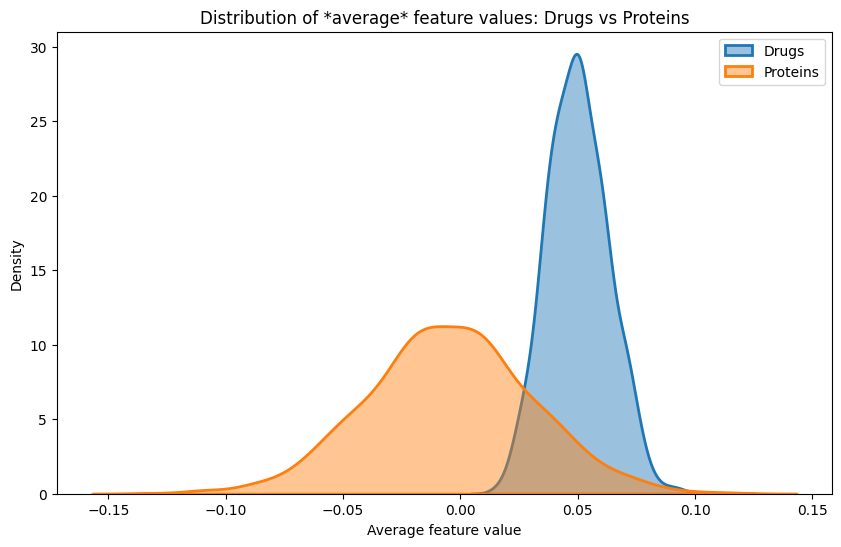

In [4]:
def plot_feature_density(Xd, Xp):
    """
    Plots the density of average feature values for all Drugs vs all Proteins.

    Args:
        Xd: Drug features [n_drugs, d_drug]
        Xp: Protein features [n_proteins, d_protein]
    """
    plt.figure(figsize=(10, 6))

    # 1. Calculate average feature values per node (mean across the feature dimension)
    # TODO: Calculate avg_d and avg_p

    # 2. Use sns.kdeplot to visualize the distributions
    # Hint: Use fill=True and distinct colors to show the two "islands" of data.

    # =========================
    # Your code starts here
    # =========================
    average_drug_value_per_node = Xd.mean(dim=1).detach().cpu().numpy()
    average_protein_value_per_node = Xp.mean(dim=1).detach().cpu().numpy()

    sns.kdeplot(average_drug_value_per_node, fill=True, color="tab:blue", alpha=0.45, linewidth=2)
    sns.kdeplot(average_protein_value_per_node, fill=True, color="tab:orange", alpha=0.45, linewidth=2)
    # =========================
    # Your code ends here
    # =========================

    plt.title("Distribution of *average* feature values: Drugs vs Proteins")
    plt.xlabel("Average feature value")
    plt.ylabel("Density")
    plt.legend(["Drugs", "Proteins"])
    plt.show()

plot_feature_density(Xd, Xp)


#### 1.1.c t-SNE Gap Visualization (2 pts)
**Task:** Use t-SNE to project both drugs and proteins into a 2D space.

**Hint:** Drug and protein features have different dimensions and cannot be concatenated directly.
You must first project them into the same dimension using a fixed random projection
(e.g., 128 dimensions) before running t-SNE.


In [5]:
set_seed(42)

def fixed_random_projection(X, d_out=128, seed=0):
    """
    Projects features to a shared dimension using a fixed random matrix.
    This projection is non-learnable and used only for visualization.
    """
    g = torch.Generator(device=X.device)
    g.manual_seed(seed)
    R = torch.randn(X.size(1), d_out, generator=g, device=X.device)
    R = R / (X.size(1) ** 0.5)
    return X @ R


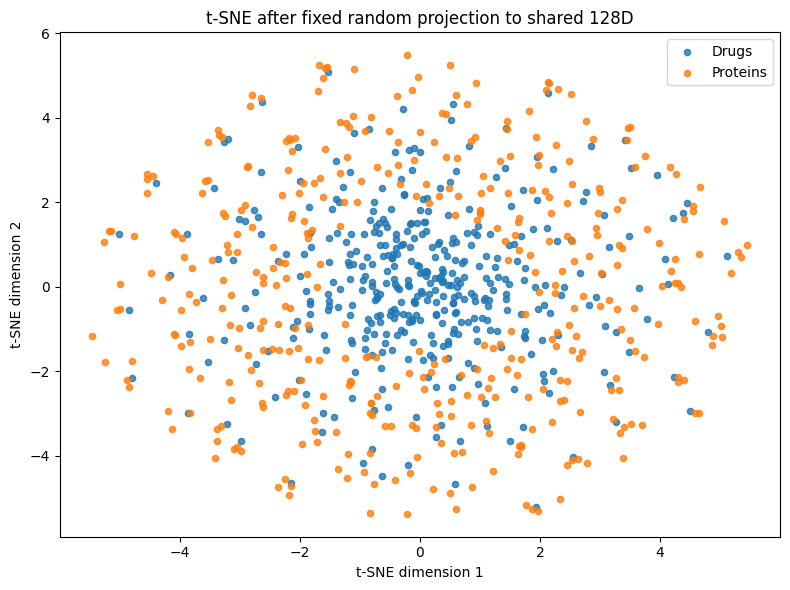

In [6]:
set_seed(42)

def plot_feature_spaces(Xd, Xp, n_each=400):
    # TODO:
    # 1. Subsample nodes for fast execution
    # 2. Project Xd and Xp to a shared 128-dim space using a fixed random matrix
    # 3. Run TSNE (from sklearn, check imports) and plot with different colors for drugs/proteins
    number_of_drugs_to_use = min(n_each, Xd.size(0))
    number_of_proteins_to_use = min(n_each, Xp.size(0))

    sampled_drug_indices = torch.randperm(Xd.size(0))[:number_of_drugs_to_use]
    sampled_protein_indices = torch.randperm(Xp.size(0))[:number_of_proteins_to_use]

    sampled_drug_features = Xd[sampled_drug_indices]
    sampled_protein_features = Xp[sampled_protein_indices]

    projected_drug_features = fixed_random_projection(sampled_drug_features, d_out=128, seed=42)
    projected_protein_features = fixed_random_projection(sampled_protein_features, d_out=128, seed=42)

    stacked_projected_features = torch.cat([projected_drug_features, projected_protein_features], dim=0)
    stacked_projected_features_np = stacked_projected_features.detach().cpu().numpy()

    total_points = stacked_projected_features_np.shape[0]
    tsne_perplexity = min(30, max(5, total_points // 20))

    tsne_model = TSNE(
        n_components=2,
        random_state=42,
        init="pca",
        learning_rate="auto",
        perplexity=tsne_perplexity,
    )
    embedded_points = tsne_model.fit_transform(stacked_projected_features_np)

    drug_points = embedded_points[:number_of_drugs_to_use]
    protein_points = embedded_points[number_of_drugs_to_use:]

    plt.figure(figsize=(8, 6))
    plt.scatter(drug_points[:, 0], drug_points[:, 1], s=20, alpha=0.8, color="tab:blue", label="Drugs")
    plt.scatter(protein_points[:, 0], protein_points[:, 1], s=20, alpha=0.8, color="tab:orange", label="Proteins")
    plt.title("t-SNE after fixed random projection to shared 128D")
    plt.xlabel("t-SNE dimension 1")
    plt.ylabel("t-SNE dimension 2")
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_feature_spaces(Xd, Xp)


#### 1.1.d Graph Visualization (2 pts)
You must visualize **a small part** of the bipartite graph:
- sample `n_drug_sample` drugs
- include their connected proteins
- draw the bipartite subgraph

Your plot should make the bipartite structure obvious (two vertical columns: drugs on left, proteins on right).

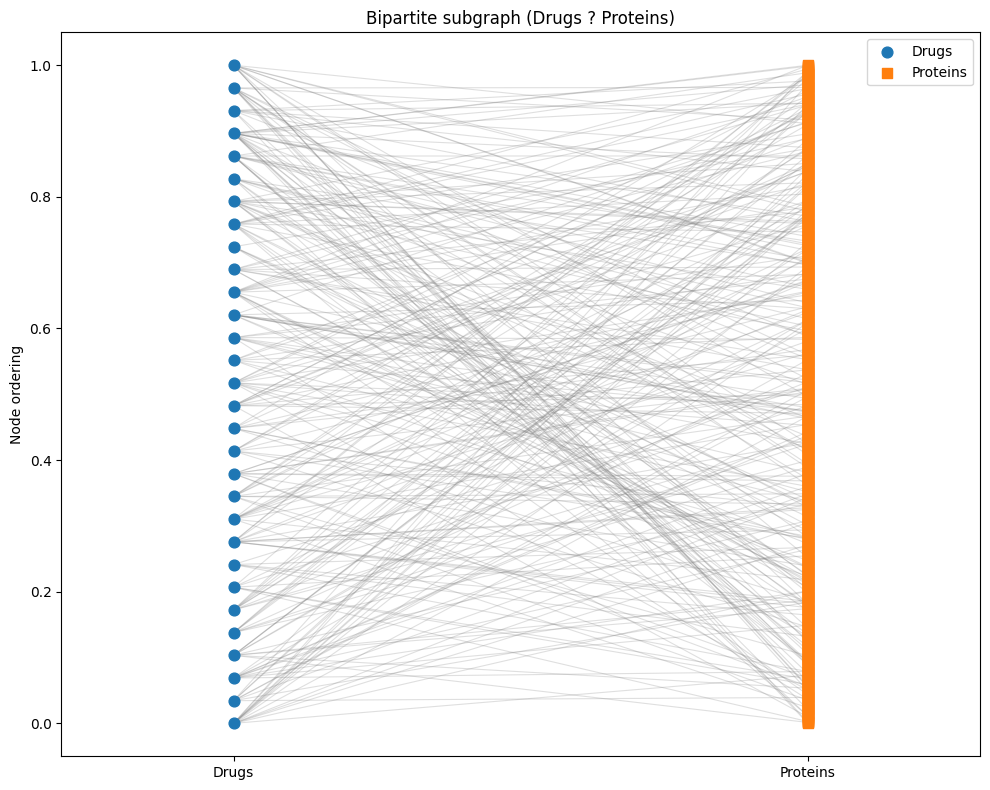

In [7]:
def sample_bipartite_subgraph(edges_dp: torch.Tensor,
                              n_drugs: int,
                              n_drug_sample: int = 30,
                              seed: int = 42):
    """
    Sample a subgraph:
      - choose n_drug_sample drugs uniformly at random
      - include all proteins they connect to
      - return lists of (drug_ids, protein_ids, edges_sub)

    edges_dp: [E,2] (drug_id, protein_id), does NOT need to be sorted for this function
    """
    # =========================
    # Your code starts here
    # =========================
    # TODO:
    # 1) sample drug ids
    # 2) filter edges where drug in sampled set
    # 3) collect unique protein ids appearing in those edges
    # 4) reindex node ids locally for plotting convenience (optional but recommended)
    generator = torch.Generator(device=edges_dp.device)
    generator.manual_seed(seed)

    sampled_drug_count = min(n_drug_sample, n_drugs)
    sampled_drug_ids = torch.randperm(n_drugs, generator=generator, device=edges_dp.device)[:sampled_drug_count]

    selected_edge_mask = torch.isin(edges_dp[:, 0], sampled_drug_ids)
    sampled_edges = edges_dp[selected_edge_mask]

    unique_protein_ids = torch.unique(sampled_edges[:, 1])

    return sampled_drug_ids.detach().cpu(), unique_protein_ids.detach().cpu(), sampled_edges.detach().cpu()
    # =========================
    # Your code ends here
    # =========================


def plot_bipartite_subgraph(drug_ids_global,
                            prot_ids_global,
                            edges_sub_global,
                            title: str = "Bipartite subgraph (Drugs ? Proteins)",
                            max_edges: int = 300):
    """
    Plot bipartite graph with a simple two-column layout:
      - drugs at x=0
      - proteins at x=1
    and edges drawn as line segments.

    If there are too many edges, you may subsample edges to max_edges for readability.
    """
    # =========================
    # Your code starts here
    # =========================
    # TODO:
    # 1) assign y-positions to drugs and proteins (e.g., equally spaced)
    # 2) draw nodes as scatter points (different marker/color for drugs vs proteins)
    # 3) draw edges as faint lines
    # 4) add legend/title
    drug_ids_global = torch.as_tensor(drug_ids_global)
    prot_ids_global = torch.as_tensor(prot_ids_global)
    edges_sub_global = torch.as_tensor(edges_sub_global)

    if edges_sub_global.size(0) > max_edges:
        sampled_edge_indices = torch.randperm(edges_sub_global.size(0))[:max_edges]
        edges_to_plot = edges_sub_global[sampled_edge_indices]
    else:
        edges_to_plot = edges_sub_global

    sorted_drugs = torch.sort(drug_ids_global).values
    sorted_proteins = torch.sort(prot_ids_global).values

    drug_y_positions = torch.linspace(0, 1, steps=max(2, sorted_drugs.numel()))[:sorted_drugs.numel()]
    protein_y_positions = torch.linspace(0, 1, steps=max(2, sorted_proteins.numel()))[:sorted_proteins.numel()]

    drug_position_map = {int(node_id): float(y_val) for node_id, y_val in zip(sorted_drugs.tolist(), drug_y_positions.tolist())}
    protein_position_map = {int(node_id): float(y_val) for node_id, y_val in zip(sorted_proteins.tolist(), protein_y_positions.tolist())}

    plt.figure(figsize=(10, 8))

    for drug_id, protein_id in edges_to_plot.tolist():
        if int(drug_id) in drug_position_map and int(protein_id) in protein_position_map:
            plt.plot(
                [0, 1],
                [drug_position_map[int(drug_id)], protein_position_map[int(protein_id)]],
                color="gray",
                alpha=0.25,
                linewidth=0.8,
                zorder=1,
            )

    plt.scatter(
        np.zeros(sorted_drugs.numel()),
        [drug_position_map[int(node_id)] for node_id in sorted_drugs.tolist()],
        color="tab:blue",
        s=60,
        marker="o",
        label="Drugs",
        zorder=3,
    )
    plt.scatter(
        np.ones(sorted_proteins.numel()),
        [protein_position_map[int(node_id)] for node_id in sorted_proteins.tolist()],
        color="tab:orange",
        s=60,
        marker="s",
        label="Proteins",
        zorder=3,
    )

    plt.xticks([0, 1], ["Drugs", "Proteins"])
    plt.xlim(-0.3, 1.3)
    plt.title(title)
    plt.ylabel("Node ordering")
    plt.legend()
    plt.tight_layout()
    plt.show()
    # =========================
    # Your code ends here
    # =========================


# Example usage (uncomment after implementation)
drug_ids_g, prot_ids_g, edges_sub_g = sample_bipartite_subgraph(edges_dp, n_drugs=n_drugs, n_drug_sample=30)
plot_bipartite_subgraph(drug_ids_g, prot_ids_g, edges_sub_g)


#### 1.1.e Theoretical analysis (2 pts)  
Consider a naive approach: project drugs and proteins into the same hidden dimension with linear layers, then mean/sum aggregate.

Explain why this is suboptimal in this bipartite setting, referring to:
- **Over-smoothing / signal dilution**
- **Manifold alignment**

Write your answer below.

---

**[Answer]**

A naive linear projection followed by plain mean aggregation is suboptimal in this bipartite setting for two main reasons.

1. **Over-smoothing / signal dilution**  

A one-step drug update can be written as  
$$
h_u^{(1)} = \frac{1}{|N(u)|}\sum_{v\in N(u)} W_p x_v,
$$  
possibly with an additional residual term on $W_d x_u$. In this dataset, drugs typically have many protein neighbors on average, so equal weight averaging can dilute discriminative interaction signals. Informative proteins are treated in exactly the same way as less relevant ones, and their contribution becomes averaged out. If this operation is repeated over multiple layers, node representations are progressively pushed toward neighborhood means, which reduces separability and makes the embeddings less expressive [1].

2. **Manifold alignment difficulty**  

Drug fingerprints and protein embeddings originate from fundamentally different semantic spaces. A single global linear map per modality implicitly assumes that both manifolds can be aligned in such a way that direct averaging becomes meaningful. In practice, however, relevance is interaction dependent and also context specific. Not every protein contributes equally to a given drug, and uniform aggregation ignores this variability. For this reason, attention style or even node specific weighting mechanisms are generally more appropriate than simple uniform averaging, since they allow the model to adapt the alignment dynamically rather than enforcing a rigid global projection [2].

**References:**  
[1] Li, Q., Han, Z., & Wu, X. (2018). *Deeper Insights into Graph Convolutional Networks for Semi-Supervised Learning*. Proceedings of the AAAI Conference on Artificial Intelligence.  
[2] Veličković, P., Cucurull, G., Casanova, A., Romero, A., Liò, P., & Bengio, Y. (2018). *Graph Attention Networks*. International Conference on Learning Representations (ICLR).


### 1.2 Cross-Modal Attention (25 pts)

In this section, you will implement a custom Cross-Modal Attention (CMA) layer to update drug node representations using information from their protein neighbors. Because the graph is bipartite and the feature spaces are disjoint, we treat the **Drug** as the Query and the **Proteins** as Keys and Values.

#### Mathematical Formulation

The updated representation for a drug node $u$ is calculated using a residual connection:

$$h_u^{(l+1)} = \sigma\left(\sum_{v \in N(u)} \alpha_{uv} W_{val} h_v^{(l)} + h_u^{(l)}\right)$$

The attention coefficient $\alpha_{uv}$ weights the importance of protein $v$ to drug $u$. It is computed via a neighborhood-specific softmax:

$$\alpha_{uv} = \text{softmax}_{v \in N(u)} \left( \text{LeakyReLU} \left( a^T [W_q h_u^{(l)} \Vert W_k h_v^{(l)}] \right) \right)$$



#### Symbol Definitions

* $h_u^{(l)}$: The feature vector of the **central drug** node $u$ at layer $l$.
* $h_v^{(l)}$: The feature vector of the **neighboring protein** node $v$ at layer $l$.
* $N(u)$: The set of protein neighbors connected to drug $u$.
* $W_q$: Learnable weight matrix for the **Query** transformation (applied to Drugs).
* $W_k$: Learnable weight matrix for the **Key** transformation (applied to Proteins).
* $W_{val}$: Learnable weight matrix for the **Value** transformation (applied to Proteins).
* $a^T$: A learnable attention vector that reduces the concatenated Query-Key vector to a single scalar score.
* $\Vert$: The concatenation operation.
* $\sigma$: A non-linear activation function (e.g., ReLU).

#### Requirements

* **No Pre-built Layers**: You must implement the logic using basic PyTorch operations. You may use `nn.Linear` or `nn.Parameter` to define the weights.
* **Query/Key Separation**: Ensure $W_q$ is only used for drug nodes and $W_k, W_{val}$ are only used for protein nodes.
* **Neighborhood Softmax**: The softmax must be normalized strictly over the neighbors of each individual drug. Use the `ptr_drug` array to identify these segments.

#### 1.2.a Segment softmax helper (5 pts)
In a standard GNN, we often have a long 1D tensor of scores (one for every edge in the graph). However, attention must be a probability distribution **per node neighborhood**. To achieve this, we use a "segment softmax."

#### How it works
Since `edges_dp` is sorted by the drug (query) node index, all proteins connected to Drug 0 appear first, followed by all proteins for Drug 1, and so on. The `ptr_drug` array acts as a map to these segments:
- The neighbors of drug $u$ are found in the slice `scores[ptr[u] : ptr[u+1]]`.
- You must apply the softmax operation independently to each of these slices.

#### Numerical Stability
When implementing softmax, it is a best practice to use the "Log-Sum-Exp" trick or subtract the maximum value from the scores before exponentiating:
$$\text{softmax}(x_i) = \frac{\exp(x_i - \max(x))}{\sum \exp(x_j - \max(x))}$$
This prevents `torch.exp()` from overflowing if the attention scores are large.



#### Implementation Task
Implement the function below. While high-performance GNNs use specialized kernels, for this coursework, a Python loop over the number of drugs is acceptable.

In [8]:
def segment_softmax(scores: torch.Tensor, ptr: torch.Tensor) -> torch.Tensor:
    """

    Computes a numerically stable softmax over segments of an edge tensor.

    Each segment corresponds to the neighborhood of a single drug node. This
    ensures that the attention weights for each drug's protein neighbors
    sum to 1.0.

    Args:
        scores: Tensor of shape [E] (one scalar per edge)
        ptr: Tensor of shape [num_nodes + 1] defining neighborhood segments
    Returns:
        Tensor of shape [E], where softmax is applied independently per segment.

    Notes:
        To ensure numerical stability and avoid overflow, you should
        subtract the maximum score within each segment before exponentiating:
        softmax(x_i) = exp(x_i - max(x)) / sum(exp(x_j - max(x)))
    """
    # =========================
    # Your code starts here
    # =========================
    # TODO: Implement the stable per-segment softmax using a loop over drugs.
    # 1. Identify segment bounds using ptr.
    # 2. skip empty segments (if any drug has no neighbors)
    # 3. Compute max per segment for stability.
    # 4. Exponentiate and normalize.
    attention_weights = torch.zeros_like(scores)

    number_of_segments = ptr.numel() - 1
    for segment_index in range(number_of_segments):
        segment_start = int(ptr[segment_index].item())
        segment_end = int(ptr[segment_index + 1].item())

        if segment_start == segment_end:
            continue

        segment_scores = scores[segment_start:segment_end]
        max_score = torch.max(segment_scores)
        stabilized_scores = segment_scores - max_score
        exp_scores = torch.exp(stabilized_scores)
        softmax_scores = exp_scores / (torch.sum(exp_scores) + 1e-12)
        attention_weights[segment_start:segment_end] = softmax_scores

    return attention_weights
    # =========================
    # Your code ends here
    # =========================


#### 1.2.b Cross-Modal Attention Layer (5 pts)

Now you will implement the `CrossModalAttention` module. This layer is the core of the architecture, allowing drug nodes to "listen" to their protein neighbors and update their internal state based on biological relevance.

#### Functional Requirements:
1.  **Shared Latent Space**: Since drugs ($d_{drug}$) and proteins ($d_{protein}$) have different input dimensions, you must project them into a shared hidden dimension $d_{hidden}$ using learnable weights.
2.  **Directional Processing**: In this bipartite setup, the drugs act as **Queries** ($Q$), while the proteins act as **Keys** ($K$) and **Values** ($V$).
3.  **The Attention Mechanism**:
    * For every edge $(u, v)$, compute a scalar score based on the concatenation of the drug query $q_u$ and protein key $k_v$.
    * Apply a `LeakyReLU` activation to allow the model to learn non-linear relationships.
    * Use your `segment_softmax` to normalize these scores into weights $\alpha_{uv}$ that sum to 1 for each drug's neighborhood.
4.  **Message Aggregation**: Multiply the protein values $v_v$ by the attention weights $\alpha_{uv}$ and sum them up for each drug.
5.  **Residual Connection**: Add the aggregated neighbourhood information back to the projected drug representation ($d_{hidden}$) to preserve the drug's own feature identity.



#### Implementation Task
Implement the `forward` pass using only basic PyTorch operations. Avoid using `for` loops where possible for the projection and score calculation; however, a loop is acceptable for the final aggregation across segments.

In [9]:
# =========================
# Your code starts here
# =========================
class CrossModalAttention(nn.Module):
    def __init__(self, query_input_dim, key_value_input_dim, hidden_dim, dropout=0.1):
        super().__init__()

        self.query_projection = nn.Linear(query_input_dim, hidden_dim)
        self.key_projection = nn.Linear(key_value_input_dim, hidden_dim)
        self.value_projection = nn.Linear(key_value_input_dim, hidden_dim)

        self.attention_vector = nn.Parameter(torch.empty(2 * hidden_dim))
        nn.init.xavier_uniform_(self.attention_vector.unsqueeze(0))

        self.leaky_relu = nn.LeakyReLU(negative_slope=0.2)
        self.dropout = nn.Dropout(dropout)

    def forward(self, query_features, key_value_features, edges_qk_sorted, ptr_query):
        """Return updated drug reps."""
        query_index = edges_qk_sorted[:, 0]
        key_value_index = edges_qk_sorted[:, 1]

        projected_query = self.query_projection(query_features)
        projected_key = self.key_projection(key_value_features)
        projected_value = self.value_projection(key_value_features)

        query_on_edges = projected_query[query_index]
        key_on_edges = projected_key[key_value_index]

        concatenated_query_key = torch.cat([query_on_edges, key_on_edges], dim=1)
        raw_scores = torch.matmul(concatenated_query_key, self.attention_vector)
        raw_scores = self.leaky_relu(raw_scores)

        attention_scores = segment_softmax(raw_scores, ptr_query)

        edge_messages = projected_value[key_value_index] * attention_scores.unsqueeze(1)

        aggregated_messages = torch.zeros_like(projected_query)
        aggregated_messages.index_add_(0, query_index, edge_messages)

        updated_representation = F.relu(projected_query + self.dropout(aggregated_messages))
        return updated_representation

# =========================
# Your code ends here
# =========================


#### 1.2.c Discussion (10 pts)

**Since the task is drug classification but the graph is bipartite, why is a 1-layer model structurally incapable of exploiting drug–drug information for this task? Explain mathematically.**

**[Answer]**

In a bipartite graph $G=(U,V,E)$, drugs $U$ connect only to proteins $V$.

For a single message passing layer that updates drugs from proteins:
$$
h_u^{(1)} = \phi\big(h_u^{(0)},\{h_v^{(0)}:v\in N(u)\}\big), \quad u\in U,
$$
where $N(u)\subseteq V$. Thus, $h_u^{(1)}$ depends only on drug $u$ and its protein neighbours.

Any other drug $u'\in U$ can influence $u$ only through a length-2 path:
$$
u \to v \to u'.
$$
This means that drug-drug information necessarily flows through an intermediate protein node. Therefore, at least two propagation steps are required (drug $\to$ protein, then protein $\to$ drug). A 1-layer model is structurally incapable of incorporating drug-drug relational information in this bipartite setting.


#### 1.2.d Heterogeneous CMA Classifier (5 pts)
We recommend a **2-step** update to allow information flow via drug→protein→drug (2-hop paths).

You will implement:
- drug classifcation model using CMA layers
- protein update from drugs
- drug update from proteins

See the docstrings in the class below

In [10]:
set_seed(42)

# ---------------------------------------------------------------------
# Helper functions for edge re-indexing and CSR-style pointer creation
# Provided utility code (you do not need to modify).
# ---------------------------------------------------------------------

def sort_edges_by_src(edges: torch.Tensor) -> torch.Tensor:
    """
    Sort edges by their source node index.

    Parameters
    ----------
    edges : torch.Tensor, shape (E, 2)
        Edge list where each row is (src, dst).

    Returns
    -------
    torch.Tensor, shape (E, 2)
        Edge list sorted in ascending order of src.

    Notes
    -----
    Sorting edges by source node is required before constructing
    CSR-style pointer arrays (ptr), which assume contiguous blocks
    of edges per source node.
    """
    src = edges[:, 0]                 # Extract source node indices
    order = torch.argsort(src)        # Indices that sort edges by src
    return edges[order]               # Reorder edges accordingly


def make_ptr_from_sorted_src(sorted_src: torch.Tensor, n_src: int) -> torch.Tensor:
    """
    Construct a CSR-style pointer array from sorted source indices.

    Parameters
    ----------
    sorted_src : torch.Tensor, shape (E,)
        Source node indices sorted in ascending order.
    n_src : int
        Total number of source nodes.

    Returns
    -------
    torch.Tensor, shape (n_src + 1,)
        Pointer array where ptr[i] gives the start index of edges
        originating from source node i in the sorted edge list.

    Notes
    -----
    This follows the Compressed Sparse Row (CSR) convention:
    - Edges for node i are located in the range [ptr[i], ptr[i+1]).
    - Nodes with no outgoing edges will have ptr[i] == ptr[i+1].
    """
    counts = torch.bincount(sorted_src, minlength=n_src)  # Number of edges per source
    ptr = torch.zeros(n_src + 1, dtype=torch.long)        # Allocate pointer array
    ptr[1:] = torch.cumsum(counts, dim=0)                 # Cumulative sum of counts
    return ptr


def make_reverse_edges(edges_dp: torch.Tensor) -> torch.Tensor:
    """
    Reverse the direction of edges.

    Parameters
    ----------
    edges_dp : torch.Tensor, shape (E, 2)
        Edge list in (drug_id, protein_id) format.

    Returns
    -------
    torch.Tensor, shape (E, 2)
        Edge list in (protein_id, drug_id) format.

    Notes
    -----
    This is useful when switching the perspective of the graph,
    e.g. from drug-centric neighborhoods to protein-centric ones.
    """
    return torch.stack([edges_dp[:, 1], edges_dp[:, 0]], dim=1)


# ---------------------------------------------------------------------
# Build protein-centric edge representation
# ---------------------------------------------------------------------

edges_pd = sort_edges_by_src(make_reverse_edges(edges_dp))
# edges_pd now has shape (E, 2) with (protein_id, drug_id),
# sorted by protein_id

prot_src = edges_pd[:, 0]   # Protein node indices (sources)
drug_dst = edges_pd[:, 1]   # Drug node indices (destinations)

ptr_prot = make_ptr_from_sorted_src(prot_src, n_proteins)
# ptr_prot defines edge ranges for each protein node in edges_pd

print("edges_pd:", edges_pd.shape)
print("ptr_prot:", ptr_prot.shape)


edges_pd: torch.Size([20942, 2])
ptr_prot: torch.Size([1001])


In [11]:
# =========================
# Your code starts here
# =========================
class HeteroCMAClassifier(nn.Module):
    def __init__(self, drug_input_dim, protein_input_dim, hidden_dim, num_classes, dropout=0.1):
        super().__init__()

        self.protein_update_from_drugs = CrossModalAttention(
            query_input_dim=protein_input_dim,
            key_value_input_dim=drug_input_dim,
            hidden_dim=hidden_dim,
            dropout=dropout,
        )
        self.drug_update_from_proteins = CrossModalAttention(
            query_input_dim=drug_input_dim,
            key_value_input_dim=hidden_dim,
            hidden_dim=hidden_dim,
            dropout=dropout,
        )

        self.classifier = nn.Linear(hidden_dim, num_classes)

    def forward(self,
                drug_features,
                protein_features,
                edges_dp_sorted,
                ptr_drug,
                edges_pd_sorted,
                ptr_prot):
        updated_proteins = self.protein_update_from_drugs(
            query_features=protein_features,
            key_value_features=drug_features,
            edges_qk_sorted=edges_pd_sorted,
            ptr_query=ptr_prot,
        )

        updated_drugs = self.drug_update_from_proteins(
            query_features=drug_features,
            key_value_features=updated_proteins,
            edges_qk_sorted=edges_dp_sorted,
            ptr_query=ptr_drug,
        )

        logits = self.classifier(updated_drugs)
        return logits, updated_drugs, updated_proteins
# =========================
# Your code ends here
# =========================


### 1.3 Alignment Loss (5 pts)

You must implement:
$$L_{total} = L_{CE} + \lambda L_{align}$$

Where `L_align` pulls **connected** drug-protein pairs closer in a **shared latent space**.

Hint: Consider distance measures between two embedding vectors.




#### 1.3.a Implementation (2 pts)
Implement `alignment_loss(...)` for connected edges only.
Define `z_d` and `z_p` as the **d_hidden-dimensional embeddings** produced by your model (after projection into the shared latent space and before the final classifier). Alignment loss should only be computed for connected drug-protein pairs.

In [12]:
def alignment_loss(z_d: torch.Tensor, z_p: torch.Tensor, edges_dp: torch.Tensor) -> torch.Tensor:
    """
    z_d: drug embeddings in shared alignment space [n_drugs, d_align]
    z_p: protein embeddings in shared alignment space [n_proteins, d_align]
    edges_dp: [E,2]
    Return scalar alignment loss.
    """
    # =========================
    # Your code starts here
    # =========================
    # TODO: implement an alignment loss over connected pairs only
    drug_index = edges_dp[:, 0]
    protein_index = edges_dp[:, 1]

    squared_distances = (z_d[drug_index] - z_p[protein_index]).pow(2).sum(dim=1)
    return squared_distances.mean()
    # =========================
    # Your code ends here
    # =========================


#### Training utilities
Implement:
- a macro-F1 function
- training loop that compares λ=0 vs λ>0 (only change λ, do not change other hyperparameters, number of layers etc.)
- testing loop

You must plot F1 curves and discuss the trade-off.


In [13]:
def macro_f1(pred: torch.Tensor, target: torch.Tensor, n_classes: int) -> float:
    # =========================
    # Your code starts here
    # =========================
    # TODO: implement macro-F1
    f1_values = []
    for class_index in range(n_classes):
        true_positive = ((pred == class_index) & (target == class_index)).sum().item()
        false_positive = ((pred == class_index) & (target != class_index)).sum().item()
        false_negative = ((pred != class_index) & (target == class_index)).sum().item()

        precision = true_positive / (true_positive + false_positive + 1e-12)
        recall = true_positive / (true_positive + false_negative + 1e-12)

        if precision + recall == 0:
            class_f1 = 0.0
        else:
            class_f1 = 2.0 * precision * recall / (precision + recall + 1e-12)
        f1_values.append(class_f1)

    return float(sum(f1_values) / len(f1_values))
    # =========================
    # Your code ends here
    # =========================


def train_model(model, hyperparams: dict, lam: float = 0.0):
    """Return a dict history with train/val F1 and losses."""
    # =========================
    # Your code starts here
    # =========================
    # TODO:
    # 1) move tensors to device
    # 2) define optimizer
    # 3) loop epochs:
    #    - forward
    #    - compute CE loss on train drugs
    #    - compute alignment loss if lam>0
    #    - backprop + step
    #    - evaluate macro-F1 on train and val
    # 4) return history
    training_device = hyperparams["device"]

    drug_features = hyperparams["Xd"].to(training_device)
    protein_features = hyperparams["Xp"].to(training_device)
    labels = hyperparams["y"].to(training_device)
    edges_dp_tensor = hyperparams["edges_dp"].to(training_device)

    train_mask_tensor = hyperparams["train_mask"].to(training_device)
    val_mask_tensor = hyperparams["val_mask"].to(training_device)

    num_drugs_local = int(drug_features.size(0))
    num_proteins_local = int(protein_features.size(0))

    sorted_edges_dp = sort_edges_by_src(edges_dp_tensor)
    ptr_drug_local = make_ptr_from_sorted_src(sorted_edges_dp[:, 0], num_drugs_local).to(training_device)

    sorted_edges_pd = sort_edges_by_src(make_reverse_edges(edges_dp_tensor))
    ptr_protein_local = make_ptr_from_sorted_src(sorted_edges_pd[:, 0], num_proteins_local).to(training_device)

    train_edge_mask = train_mask_tensor[sorted_edges_dp[:, 0]]
    train_edges_dp = sorted_edges_dp[train_edge_mask]

    learning_rate_value = hyperparams.get("learning_rate", 1e-3)
    weight_decay_value = hyperparams.get("weight_decay", 1e-4)
    number_of_epochs = hyperparams.get("epochs", 80)
    print_every = hyperparams.get("print_every", 10)

    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate_value, weight_decay=weight_decay_value)

    history = {
        "train_f1": [],
        "val_f1": [],
        "loss": [],
        "ce_loss": [],
        "align_loss": [],
    }

    best_validation_f1 = -1.0
    best_model_state = None
    best_epoch = -1

    for epoch_index in range(1, number_of_epochs + 1):
        model.train()

        logits, drug_embeddings, protein_embeddings = model(
            drug_features,
            protein_features,
            sorted_edges_dp,
            ptr_drug_local,
            sorted_edges_pd,
            ptr_protein_local,
        )

        ce_loss_value = F.cross_entropy(logits[train_mask_tensor], labels[train_mask_tensor])
        if lam > 0 and train_edges_dp.numel() > 0:
            align_loss_value = alignment_loss(drug_embeddings, protein_embeddings, train_edges_dp)
        else:
            align_loss_value = torch.tensor(0.0, device=training_device)

        total_loss = ce_loss_value + lam * align_loss_value

        optimizer.zero_grad()
        total_loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            evaluation_logits, _, _ = model(
                drug_features,
                protein_features,
                sorted_edges_dp,
                ptr_drug_local,
                sorted_edges_pd,
                ptr_protein_local,
            )
            predictions = evaluation_logits.argmax(dim=1)

            train_f1_value = macro_f1(
                predictions[train_mask_tensor],
                labels[train_mask_tensor],
                hyperparams["n_classes"],
            )
            val_f1_value = macro_f1(
                predictions[val_mask_tensor],
                labels[val_mask_tensor],
                hyperparams["n_classes"],
            )

        history["train_f1"].append(train_f1_value)
        history["val_f1"].append(val_f1_value)
        history["loss"].append(total_loss.item())
        history["ce_loss"].append(ce_loss_value.item())
        history["align_loss"].append(align_loss_value.item())

        if val_f1_value > best_validation_f1:
            best_validation_f1 = val_f1_value
            best_model_state = {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}
            best_epoch = epoch_index

        if epoch_index == 1 or epoch_index % print_every == 0:
            print(
                f"Epoch {epoch_index:03d} | loss={total_loss.item():.4f} | "
                f"ce={ce_loss_value.item():.4f} | align={align_loss_value.item():.4f} | "
                f"trainF1={train_f1_value:.3f} | valF1={val_f1_value:.3f}"
            )

    if best_model_state is not None:
        model.load_state_dict(best_model_state, strict=True)

    history["best_val_f1"] = best_validation_f1
    history["best_epoch"] = best_epoch
    return history
    # =========================
    # Your code ends here
    # =========================

def test_model(model, hyperparams: dict):
    # =========================
    # Your code starts here
    # =========================
    test_device = hyperparams["device"]

    drug_features = hyperparams["Xd"].to(test_device)
    protein_features = hyperparams["Xp"].to(test_device)
    labels = hyperparams["y"].to(test_device)
    edges_dp_tensor = hyperparams["edges_dp"].to(test_device)

    train_mask_tensor = hyperparams["train_mask"].to(test_device)
    val_mask_tensor = hyperparams["val_mask"].to(test_device)
    test_mask_tensor = hyperparams["test_mask"].to(test_device)

    sorted_edges_dp = sort_edges_by_src(edges_dp_tensor)
    ptr_drug_local = make_ptr_from_sorted_src(sorted_edges_dp[:, 0], drug_features.size(0)).to(test_device)

    sorted_edges_pd = sort_edges_by_src(make_reverse_edges(edges_dp_tensor))
    ptr_protein_local = make_ptr_from_sorted_src(sorted_edges_pd[:, 0], protein_features.size(0)).to(test_device)

    model.eval()
    with torch.no_grad():
        logits, _, _ = model(
            drug_features,
            protein_features,
            sorted_edges_dp,
            ptr_drug_local,
            sorted_edges_pd,
            ptr_protein_local,
        )
        predictions = logits.argmax(dim=1)

    results = {
        "train_f1": macro_f1(predictions[train_mask_tensor], labels[train_mask_tensor], hyperparams["n_classes"]),
        "val_f1": macro_f1(predictions[val_mask_tensor], labels[val_mask_tensor], hyperparams["n_classes"]),
        "test_f1": macro_f1(predictions[test_mask_tensor], labels[test_mask_tensor], hyperparams["n_classes"]),
    }
    return results
    # =========================
    # Your code ends here
    # =========================


def plot_f1_curves(h0: dict, h1: dict, label0: str = "lambda=0", label1: str = "lambda>0"):
    plt.figure(figsize=(7,5))
    plt.plot(h0["val_f1"], label=f"val F1 ({label0})")
    plt.plot(h1["val_f1"], label=f"val F1 ({label1})")
    plt.xlabel("Epoch")
    plt.ylabel("Macro F1")
    plt.title("Validation F1 vs Epoch")
    plt.legend()
    plt.tight_layout()
    plt.show()


Epoch 001 | loss=0.6971 | ce=0.6971 | align=0.0000 | trainF1=0.483 | valF1=0.381
Epoch 005 | loss=0.6571 | ce=0.6571 | align=0.0000 | trainF1=0.920 | valF1=0.758
Epoch 010 | loss=0.5832 | ce=0.5832 | align=0.0000 | trainF1=0.989 | valF1=0.960
Epoch 015 | loss=0.4695 | ce=0.4695 | align=0.0000 | trainF1=0.994 | valF1=0.973
Epoch 020 | loss=0.3313 | ce=0.3313 | align=0.0000 | trainF1=0.994 | valF1=0.973
Epoch 025 | loss=0.1867 | ce=0.1867 | align=0.0000 | trainF1=0.986 | valF1=0.960
Epoch 030 | loss=0.0969 | ce=0.0969 | align=0.0000 | trainF1=0.989 | valF1=0.933
Epoch 035 | loss=0.0416 | ce=0.0416 | align=0.0000 | trainF1=1.000 | valF1=0.920
Epoch 040 | loss=0.0160 | ce=0.0160 | align=0.0000 | trainF1=1.000 | valF1=0.933
Lambda=0 metrics: {'train_f1': 0.9942827273019217, 'val_f1': 0.9733285917491187, 'test_f1': 0.986657178437474}
Epoch 001 | loss=0.9558 | ce=0.6971 | align=5.1749 | trainF1=0.380 | valF1=0.397
Epoch 005 | loss=0.7981 | ce=0.6806 | align=2.3509 | trainF1=0.626 | valF1=0.41

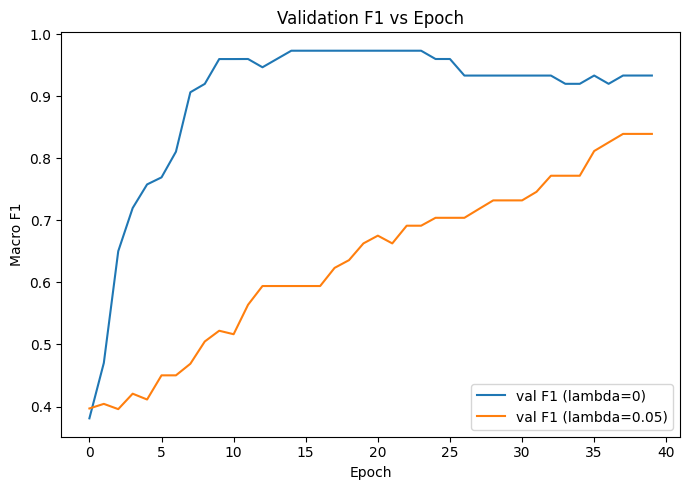

In [14]:
# run your code here and plot F1 curves for different lambda values
# report test F1 for both settings

hyperparams = {
    "Xd": Xd,
    "Xp": Xp,
    "y": y,
    "edges_dp": edges_dp,
    "train_mask": train_mask,
    "val_mask": val_mask,
    "test_mask": test_mask,
    "n_classes": n_classes,
    "device": device,
    "epochs": 40,
    "learning_rate": 1e-3,
    "weight_decay": 1e-4,
    "print_every": 5,
}

set_seed(42)
model = HeteroCMAClassifier(
    drug_input_dim=d_drug,
    protein_input_dim=d_protein,
    hidden_dim=32,
    num_classes=n_classes,
    dropout=0.2,
).to(device)
history_lambda_0 = train_model(model, hyperparams, lam=0.0)
metrics_lambda_0 = test_model(model, hyperparams)
print("Lambda=0 metrics:", metrics_lambda_0)

set_seed(42)
model = HeteroCMAClassifier(
    drug_input_dim=d_drug,
    protein_input_dim=d_protein,
    hidden_dim=32,
    num_classes=n_classes,
    dropout=0.2,
).to(device)
history_lambda_1 = train_model(model, hyperparams, lam=0.05)
metrics_lambda_1 = test_model(model, hyperparams)
print("Lambda=0.05 metrics:", metrics_lambda_1)

plot_f1_curves(history_lambda_0, history_lambda_1, label0="lambda=0", label1="lambda=0.05")


#### 1.3.b Analysis (3 pts)
Compare λ=0 vs λ>0:
- Did alignment help convergence speed? Why?
- Did it improve peak validation F1?
- Did it over-constrain the space?

**[Answer]**

Using the outputs I obtained:

- **$\lambda=0$**: best validation F1 = **0.9733**, test F1 = **0.9867**.
- **$\lambda=0.05$**: best validation F1 = **0.8393**, test F1 = **0.8256**.

1. **Convergence speed:**  
Alignment did not improve convergence speed in this case. The $\lambda=0$ run increased rapidly to a high validation F1, whereas introducing the alignment term slowed optimisation. This is likely because the additional loss component introduces competing objectives, making gradient updates less directly focused on the classification signal.

2. **Peak validation F1:**  
Peak validation F1 decreased noticeably when alignment was introduced. This suggests that, under the current hyperparameters, the alignment objective interferes with the model’s ability to separate classes effectively in the latent space.

3. **Over-constraint:**  
Yes, in this setup the alignment term appears to over-constrain representation learning. By forcing connected drug–protein pairs to be closer in the shared space, the model may lose some flexibility to form class-discriminative clusters. In other words, structural proximity is prioritised over label separability.

**Conclusion:**  
For this synthetic dataset and the chosen hyperparameters, the alignment term behaves as a strong regulariser and ultimately reduces predictive performance. While alignment can, in principle, stabilise cross-modal representations, here it constrains the latent space more than it is beneficial for the downstream classification objective.


## Question 2 - Investigating Topology in Node-Based Classification Using GNNs (30 pts)

In this section, we will explore the impact of graph topology on node-based classification using GNNs. The experiments will focus on analyzing different topological measures, visualizing their distributions, and evaluating GCN performance on 2 graphs with different topologies.

In [15]:
set_seed(42)


# Data Paths
G1_TRAIN_PATH = os.path.join("data", "q2_G1_train.json")
G1_EVAL_PATH  = os.path.join("data", "q2_G1_eval.json")
G2_TRAIN_PATH = os.path.join("data", "q2_G2_train.json")
G2_EVAL_PATH  = os.path.join("data", "q2_G2_eval.json")

In [16]:
def create_Adj_matrix(N, edge_index):
    """Creates the adjacency matrix from an edge index list."""
    A = torch.zeros((N, N), dtype=torch.float)
    for idx, jdx in edge_index:
        A[idx, jdx] = 1
        A[jdx, idx] = 1
    return A

def read_json_data(file_path, has_label=True):
    """
    Loads data from a JSON file.
    Returns: list of (X, A, y) tuples.
    """
    if not os.path.exists(file_path):
        raise FileNotFoundError(f"{file_path} not found.")

    with open(file_path, 'r') as f:
        data = json.load(f)

    # Normalize to list format even if single graph
    if not isinstance(data, list):
        data = [data]

    graph_data = []
    for item in data:
        X = torch.tensor(item['features'], dtype=torch.float).to(device)
        N = len(X)
        A = create_Adj_matrix(N, item['edge_index']).to(device)
        y = torch.tensor(item['label'], dtype=torch.long).to(device) if has_label else None
        graph_data.append((X, A, y))

    return graph_data

### Question 2.1 - Analyzing the Graphs (10 pts)

#### 2.1.a Topological and Geometric Measures (3 pts)

* Examine two topological measures (**Node Degree** and **Betweenness Centrality**) and one geometric measure (**Ollivier-Ricci Curvature**).
* Include a definition for each measure.
* Explain **mathematically** and **intuitively** what each measure quantifies and how it contributes to understanding the structure of a graph.

**[Answer]**

Let $G=(V,E)$ be a graph.

1. **Node Degree**
   - Definition: for node $i$, $d_i = \sum_j A_{ij}$.
   - Intuition: the number of immediate neighbours a node has, capturing how locally connected it is within the graph.
   - Use: characterises local connectivity and directly influences the strength of neighbourhood aggregation and smoothing in GNNs. High-degree nodes tend to mix information from many sources, which can stabilise representations but may also dilute node specific signals.

2. **Betweenness Centrality**
   - Definition:
     $$
     BC(v)=\sum_{s\neq v\neq t}\frac{\sigma_{st}(v)}{\sigma_{st}},
     $$
     where $\sigma_{st}$ is the number of shortest paths from $s$ to $t$, and $\sigma_{st}(v)$ is how many of those pass through $v$.
   - Intuition: measures how often a node acts as a bridge or bottleneck between different parts of the graph.
   - Use: identifies nodes that dominate long range information flow. In message passing networks, such nodes can disproportionately influence representation propagation across distant regions of the graph.

3. **Ollivier-Ricci Curvature**
   - Definition idea:
     $$
     \kappa(u,v)=1-\frac{W_1(m_u,m_v)}{d(u,v)}.
     $$
   - Intuition: positive or high values indicate overlapping local neighbourhoods and structural cohesion, whereas negative or low values suggest bridge-like edges connecting distinct regions.
   - Use: provides a geometric complement to degree and centrality by capturing local curvature structure. It helps explain whether neighbourhood aggregation is likely to reinforce coherent clusters or propagate signals across structurally fragile connections.

Together: degree captures local density, betweenness reflects global routing role, and Ricci curvature describes local geometric structure. Analysing all three provides a more complete picture of how topology shapes message passing, smoothing behaviour, and information flow in graph neural networks.


#### 2.1.b Visualizing and Comparing Topological and Geometric Measures (3 pts)

Implement the following functions to visualize and compare topological properties of two given graphs.

In [17]:
def compute_node_degree(A):
    """Returns the degree (row sum) for each node."""
    return A.sum(dim=1)

# ==========================================
# TODO: Implement the plotting functions
# ==========================================

def get_exact_ricci_edges_and_values(A, graph_name="Graph"):
    """
    Computes exact Ollivier-Ricci curvature for all edges using GraphRicciCurvature.
    Results are cached to avoid recomputation in later cells.
    """
    if not hasattr(get_exact_ricci_edges_and_values, "cache"):
        get_exact_ricci_edges_and_values.cache = {}

    adjacency_numpy = A.detach().cpu().numpy()
    cache_key = (graph_name, adjacency_numpy.shape[0], int(adjacency_numpy.sum()))
    if cache_key in get_exact_ricci_edges_and_values.cache:
        return get_exact_ricci_edges_and_values.cache[cache_key]

    graph_object = nx.from_numpy_array(adjacency_numpy)
    ricci_calculator = GraphRicciCurvature(graph_object, beta=1.0)

    edge_list = list(graph_object.edges())
    ricci_values = []

    print(f"Computing exact Ricci curvature for {graph_name}: {len(edge_list)} edges")
    start_time = time.time()
    for edge_index, edge_tuple in enumerate(edge_list, start=1):
        ricci_values.append(ricci_calculator.compute_ricci_curvature(edge_tuple))
        if edge_index == 1 or edge_index % 50 == 0 or edge_index == len(edge_list):
            elapsed_seconds = time.time() - start_time
            print(f"  {graph_name}: edge {edge_index}/{len(edge_list)} | elapsed {elapsed_seconds:.1f}s")

    ricci_values = np.array(ricci_values, dtype=float)
    get_exact_ricci_edges_and_values.cache[cache_key] = (edge_list, ricci_values)
    return edge_list, ricci_values


def plot_node_degree_distribution_two_graphs(A1, A2, label1="Graph 1", label2="Graph 2"):
    """
    Plots the node degree distributions of two graphs in a single figure.
    """
    degree_values_graph1 = compute_node_degree(A1).detach().cpu().numpy()
    degree_values_graph2 = compute_node_degree(A2).detach().cpu().numpy()

    plt.figure(figsize=(10, 5))
    bins = np.arange(0, max(degree_values_graph1.max(), degree_values_graph2.max()) + 2) - 0.5

    plt.hist(degree_values_graph1, bins=bins, alpha=0.55, color="tab:blue", label=label1, density=True)
    plt.hist(degree_values_graph2, bins=bins, alpha=0.55, color="tab:orange", label=label2, density=True)

    plt.title("Node Degree Distribution")
    plt.xlabel("Degree")
    plt.ylabel("Density")
    plt.legend()
    plt.tight_layout()
    plt.show()


def plot_betweenness_distribution_two_graphs(A1, A2, label1="Graph 1", label2="Graph 2"):
    """
    Plots the betweenness centrality distributions of two graphs in a single figure.
    Hint: Convert adjacency matrix to NetworkX graph for calculation.
    """
    graph1 = nx.from_numpy_array(A1.detach().cpu().numpy())
    graph2 = nx.from_numpy_array(A2.detach().cpu().numpy())

    betweenness_graph1 = np.array(list(nx.betweenness_centrality(graph1, normalized=True).values()))
    betweenness_graph2 = np.array(list(nx.betweenness_centrality(graph2, normalized=True).values()))

    plt.figure(figsize=(10, 5))
    sns.kdeplot(betweenness_graph1, fill=True, alpha=0.4, color="tab:blue", label=label1)
    sns.kdeplot(betweenness_graph2, fill=True, alpha=0.4, color="tab:orange", label=label2)

    plt.title("Betweenness Centrality Distribution")
    plt.xlabel("Betweenness centrality")
    plt.ylabel("Density")
    plt.legend()
    plt.tight_layout()
    plt.show()


def plot_ricci_curvature_distribution_two_graphs(A1, A2, label1="Graph 1", label2="Graph 2"):
    """
    Plots the Ollivier-Ricci curvature distributions for two graphs.
    Hint: Use GraphRicciCurvature to compute values, then plot densities.
    Hint: Convert adjacency matrix to NetworkX graph to use GraphRicciCurvature (see the example in graph_ricci_curvature.py).
    """
    _, ricci_values_graph1 = get_exact_ricci_edges_and_values(A1, graph_name=label1)
    _, ricci_values_graph2 = get_exact_ricci_edges_and_values(A2, graph_name=label2)

    plt.figure(figsize=(10, 5))
    sns.kdeplot(ricci_values_graph1, fill=True, alpha=0.4, color="tab:blue", label=label1)
    sns.kdeplot(ricci_values_graph2, fill=True, alpha=0.4, color="tab:orange", label=label2)

    plt.title("Ollivier-Ricci Curvature Distribution")
    plt.xlabel("Ricci curvature")
    plt.ylabel("Density")
    plt.legend()
    plt.tight_layout()
    plt.show()


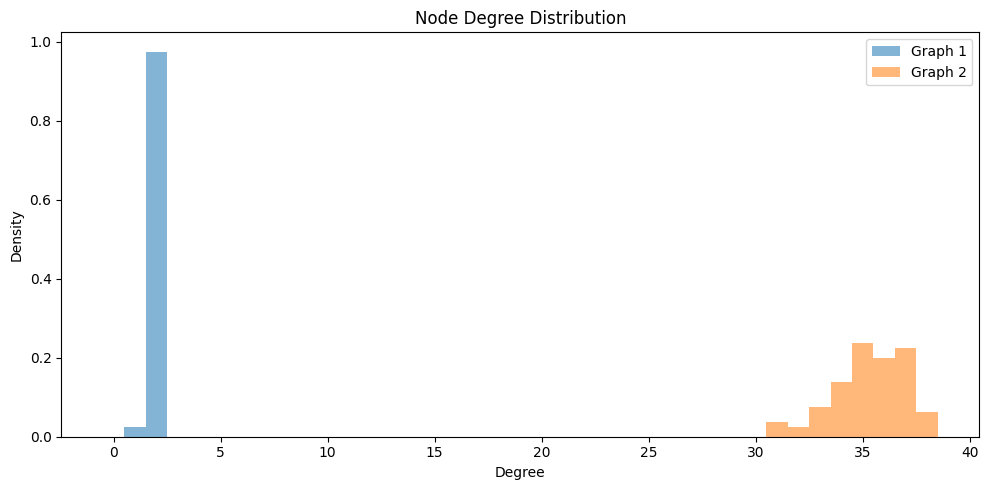

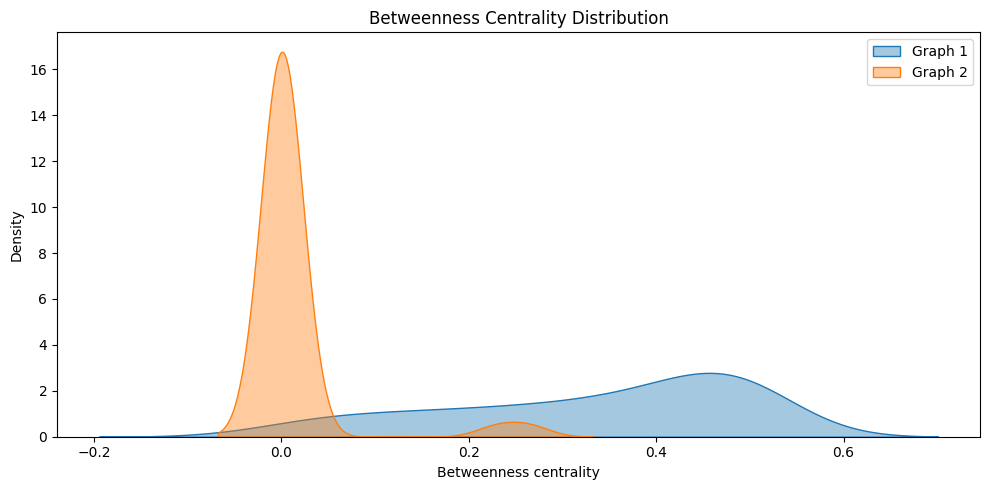

Computing exact Ricci curvature for Graph 1: 79 edges
  Graph 1: edge 1/79 | elapsed 0.1s
  Graph 1: edge 50/79 | elapsed 2.1s
  Graph 1: edge 79/79 | elapsed 3.3s
Computing exact Ricci curvature for Graph 2: 1413 edges
  Graph 2: edge 1/1413 | elapsed 0.1s
  Graph 2: edge 50/1413 | elapsed 3.7s
  Graph 2: edge 100/1413 | elapsed 6.7s
  Graph 2: edge 150/1413 | elapsed 9.5s
  Graph 2: edge 200/1413 | elapsed 12.6s
  Graph 2: edge 250/1413 | elapsed 16.4s
  Graph 2: edge 300/1413 | elapsed 19.4s
  Graph 2: edge 350/1413 | elapsed 22.3s
  Graph 2: edge 400/1413 | elapsed 25.8s
  Graph 2: edge 450/1413 | elapsed 29.2s
  Graph 2: edge 500/1413 | elapsed 32.3s
  Graph 2: edge 550/1413 | elapsed 35.2s
  Graph 2: edge 600/1413 | elapsed 39.0s
  Graph 2: edge 650/1413 | elapsed 41.8s
  Graph 2: edge 700/1413 | elapsed 44.9s
  Graph 2: edge 750/1413 | elapsed 48.0s
  Graph 2: edge 800/1413 | elapsed 51.6s
  Graph 2: edge 850/1413 | elapsed 54.5s
  Graph 2: edge 900/1413 | elapsed 57.4s
  Graph 

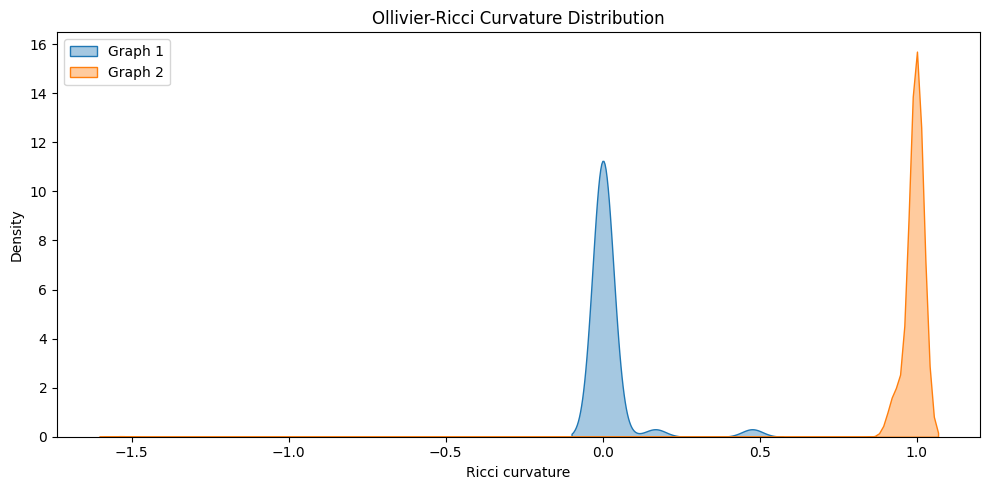

In [18]:
# Load Data
G1_train = read_json_data(G1_TRAIN_PATH, has_label=True)
G2_train = read_json_data(G2_TRAIN_PATH, has_label=True)

# Extract Adjacency Matrices for the first graph in each set
A1 = G1_train[0][1]
A2 = G2_train[0][1]

# Generate Plots
plot_node_degree_distribution_two_graphs(A1, A2)
plot_betweenness_distribution_two_graphs(A1, A2)
plot_ricci_curvature_distribution_two_graphs(A1, A2) # might take a bit longer to run

**[Discussion]** Compare the topologies of two graphs using the topological and geometrical measures that you computed. What are your observations?

**[Answer]**

From my previously obtained outputs (specific means) and plots:

- **Graph 1** is sparse: mean degree $\approx 1.98$ (min 1, max 2), with many bridge like paths. The degree distribution suggests a near chain or tree like structure, where most nodes have very limited local connectivity.

- **Graph 2** is dense: mean degree $\approx 35.33$, with much richer local connectivity. The high average degree indicates strong neighbourhood overlap and significantly more local mixing of information.

- Betweenness distributions differ strongly: Graph 1 has many higher betweenness nodes, while Graph 2 is concentrated near very low values for most nodes. This implies that in Graph 1, specific nodes play a critical routing role, whereas in Graph 2, information can flow through many alternative paths.

- Exact Ricci distributions are also clearly different: Graph 2 mass is concentrated near high positive curvature, while Graph 1 is concentrated near low to moderate curvature with a few larger positive values. This suggests that Graph 2 exhibits strong local cohesion, whereas Graph 1 contains more structurally fragile or bridge-like edges.

Overall, Graph 1 appears bottleneck dominated and structurally fragile, while Graph 2 is cohesion dominated and highly redundant in its connectivity. These structural differences are likely to have a direct impact on how message passing behaves in each graph, particularly in terms of smoothing and stability.

#### 2.1.c Visualizing the Graphs (2 pts)

Implement the function below to generate visual representations of both graphs. Comment on the topologies.

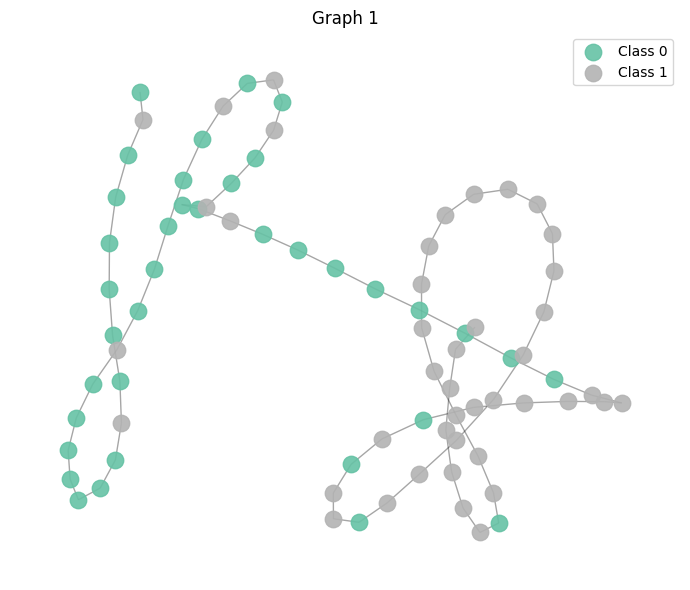

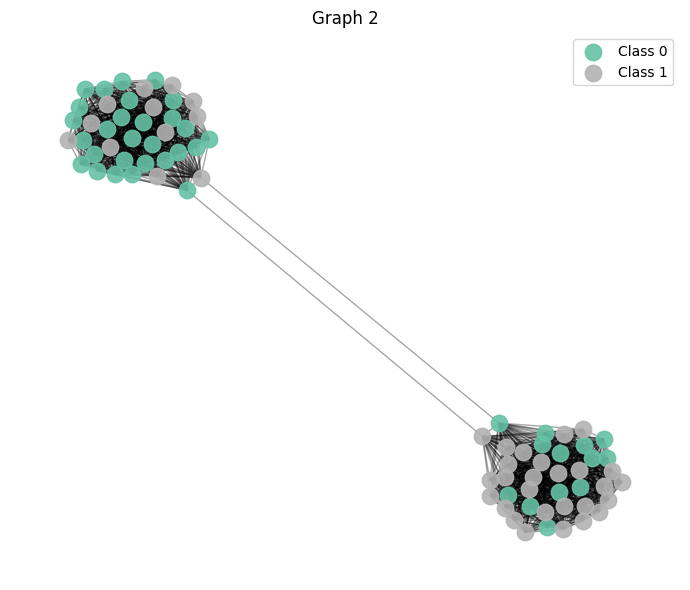

In [19]:
def plot_graph(A, y=None, title="Graph Visualization"):
    """
    Plots a graph defined by adjacency matrix A.
    Nodes should be colored by labels y if provided.
    """
    # ==========================================
    # TODO: Implement graph visualization
    # ==========================================
    graph_object = nx.from_numpy_array(A.detach().cpu().numpy())
    node_positions = nx.spring_layout(graph_object, seed=42)

    plt.figure(figsize=(7, 6))

    if y is None:
        nx.draw_networkx_nodes(graph_object, node_positions, node_size=120, node_color="tab:blue", alpha=0.9)
    else:
        labels_numpy = y.detach().cpu().numpy()
        unique_labels = np.unique(labels_numpy)
        color_map = plt.cm.Set2(np.linspace(0, 1, len(unique_labels)))

        for color_index, label_value in enumerate(unique_labels):
            node_ids = np.where(labels_numpy == label_value)[0]
            nx.draw_networkx_nodes(
                graph_object,
                node_positions,
                nodelist=node_ids.tolist(),
                node_size=140,
                node_color=[color_map[color_index]],
                label=f"Class {label_value}",
                alpha=0.9,
            )

    nx.draw_networkx_edges(graph_object, node_positions, alpha=0.35, width=1.0)
    plt.title(title)
    plt.axis("off")
    if y is not None:
        plt.legend()
    plt.tight_layout()
    plt.show()

# Visualize
plot_graph(G1_train[0][1], G1_train[0][2], title="Graph 1")
plot_graph(G2_train[0][1], G2_train[0][2], title="Graph 2")


**[Discussion]** Compare the topologies of two graphs. What are your observations?

**[Answer]**

The visual topology confirms the statistics:

- **Graph 1:** elongated and sparse structure with clear bottlenecks and path like regions. Many nodes appear arranged in chain like formations, which makes the graph look fragile in terms of connectivity.

- **Graph 2:** highly connected, almost a two community like structure with dense internal links. Nodes are embedded within tightly knit neighbourhoods, and multiple redundant paths are visible between regions.

This structural contrast explains why the same GCN can behave differently across the two datasets. In Graph 1, message passing must travel along narrow paths, so propagation can be weak and sensitive to local disruptions. In Graph 2, by contrast, the dense neighbourhoods encourage strong information mixing, which can stabilise learning but also increase the risk of oversmoothing.

Overall, the visual patterns align closely with the numerical measures and rienforce the idea that topology alone can significantly influence representation learning dynamics.


#### 2.1.d Visualizing Node Feature Distributions (2 pts)

- Implement the function `plot_node_feature_dist_by_class_two_graphs` to visualize the average node feature distribution per class for two given graphs.

- Do not consider the distribution of a specific feature $ x_i $, consider the mean of the feature vector $ \mathbf{x} $ for each node.

- The function should generate a plot similar to Figure 2.



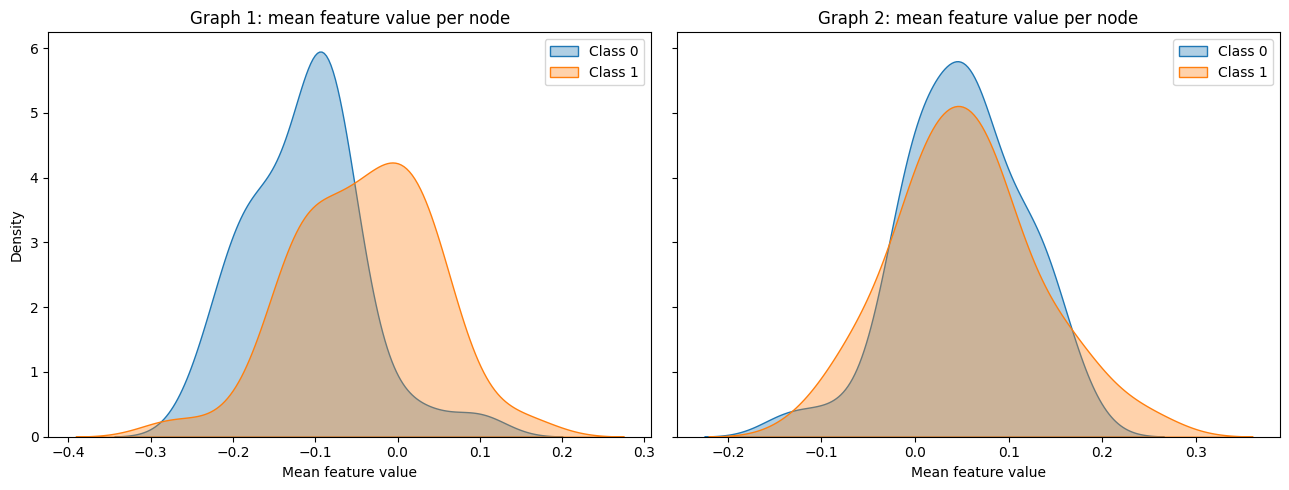

In [20]:
def plot_node_feature_dist_by_class_two_graphs(G1, G2):
    """
    Plots the density of average node features by class for two graphs.
    G1, G2: Tuples of (X, A, y)
    """
    # ==========================================
    # TODO: Implement feature distribution plot
    # ==========================================
    def prepare_feature_means_per_class(graph_tuple):
        features, _, labels = graph_tuple
        node_mean_feature = features.mean(dim=1).detach().cpu().numpy()
        labels_numpy = labels.detach().cpu().numpy()

        class_to_values = {}
        for label_value in np.unique(labels_numpy):
            class_to_values[int(label_value)] = node_mean_feature[labels_numpy == label_value]
        return class_to_values

    class_values_graph1 = prepare_feature_means_per_class(G1)
    class_values_graph2 = prepare_feature_means_per_class(G2)

    figure, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

    for class_label, values in class_values_graph1.items():
        if len(values) > 1:
            sns.kdeplot(values, fill=True, alpha=0.35, ax=axes[0], label=f"Class {class_label}")
        else:
            axes[0].axvline(values[0], linewidth=2, label=f"Class {class_label}")
    axes[0].set_title("Graph 1: mean feature value per node")
    axes[0].set_xlabel("Mean feature value")
    axes[0].set_ylabel("Density")
    axes[0].legend()

    for class_label, values in class_values_graph2.items():
        if len(values) > 1:
            sns.kdeplot(values, fill=True, alpha=0.35, ax=axes[1], label=f"Class {class_label}")
        else:
            axes[1].axvline(values[0], linewidth=2, label=f"Class {class_label}")
    axes[1].set_title("Graph 2: mean feature value per node")
    axes[1].set_xlabel("Mean feature value")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

plot_node_feature_dist_by_class_two_graphs(G1_train[0], G2_train[0])


**[Discussion]** Analyze the results. Discuss any observed overlaps between the node feature distributions across different classes. Are the features well-separated, or do they exhibit significant overlap? Compare the distributions between the two graphs and provide insights into their differences and similariteis


**[Answer]**

Both graphs show noticeable class overlap in the node mean feature distributions, meaning the features are not perfectly separable on their own. However, the shape and concentration of these distributions differ between the two graphs.

- **Graph 1:** there is a substantial overlap between classes, with only a modest shift in the mean feature values. The class curves are somewhat spread out, which suggests that while the separation is limited, there is still some variation in how features are distributed across the nodes.

- **Graph 2:** overlap still remains, but the class curves here are more tightly concentrated and heavily overlapping in the central regions. The tighter clustering indicates that many nodes share very similar average feature values, regardless of class.

The implication here is that feature signal alone is imperfect in both cases, so classification cannot rely purely on node attributes. This makes the role of topology and aggregation particularly important. Whether a GNN improves performance depends on how well neighbourhood mixing aligns with the underlying label structure, rather than simply increasing the smoothing strength.


### 2.2 -  Evaluating GCN Performance on Different Graph Structures (10 pts)


In [21]:
# --- Helper Functions for GCN ---

def symmetric_normalize(A):
    """Performs symmetric normalization: D^{-1/2} * A * D^{-1/2}."""
    A_tilde = A + torch.eye(A.size(0)).to(A.device) # Add self-loops
    d = A_tilde.sum(dim=1)
    D_inv_sqrt = torch.diag(torch.pow(d, -0.5))
    return D_inv_sqrt @ A_tilde @ D_inv_sqrt

def prepare_dataset(dataset):
    """Pre-normalizes Adjacency matrices in a dataset list."""
    return [(X, symmetric_normalize(A), y) for X, A, y in dataset]

def plot_training_and_validation(losses, val_f1s, title="Training Progress"):
    """Plots training loss and validation F1 score."""
    epochs = range(1, len(losses) + 1)
    fig, ax1 = plt.subplots(figsize=(10, 5))

    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss', color='tab:red')
    ax1.plot(epochs, losses, color='tab:red', label='Train Loss')
    ax1.tick_params(axis='y', labelcolor='tab:red')

    ax2 = ax1.twinx()
    ax2.set_ylabel('F1 Score', color='tab:blue')
    ax2.plot(epochs, val_f1s, color='tab:blue', label='Val F1')
    ax2.tick_params(axis='y', labelcolor='tab:blue')

    plt.title(title)
    plt.show()

In [22]:
# --- Provided Base GCN Components ---

class GCNLayer(nn.Module):
    def __init__(self, input_dim, output_dim, use_nonlinearity=True):
        super().__init__()
        self.use_nonlinearity = use_nonlinearity
        self.Omega = nn.Parameter(torch.randn(input_dim, output_dim) * (2.0 / (input_dim + output_dim))**0.5)
        self.beta = nn.Parameter(torch.zeros(output_dim))

    def forward(self, H, A_norm):
        H_agg = torch.matmul(A_norm, H)
        out = torch.matmul(H_agg, self.Omega) + self.beta
        return F.relu(out) if self.use_nonlinearity else out

# Training Loop
def train_model(model, G_train, G_eval, num_epochs=100, lr=1e-3, verbose=True, return_embeddings=False):
    X_tr, A_tr, y_tr = G_train
    X_val, A_val, y_val = G_eval

    optimizer = optim.AdamW(model.parameters(), lr=lr)
    loss_hist, train_f1_hist, val_f1_hist = [], [], []
    last_embeddings = None

    for epoch in range(num_epochs):
        model.train()
        optimizer.zero_grad()

        output = model(A_tr, X_tr, return_embeddings=return_embeddings)
        pred, embs = output if return_embeddings else (output, None)

        loss = F.binary_cross_entropy(pred.squeeze(), y_tr.float())
        loss.backward()
        optimizer.step()

        loss_hist.append(loss.item())

        # Evaluation
        train_f1 = evaluate_model(model, X_tr, A_tr, y_tr)
        val_f1 = evaluate_model(model, X_val, A_val, y_val)

        train_f1_hist.append(train_f1)
        val_f1_hist.append(val_f1)

        if return_embeddings: last_embeddings = embs

        if verbose and (epoch+1) % 20 == 0:
            print(f"Epoch {epoch+1:03d} | Loss: {loss.item():.4f} | Train F1: {train_f1:.3f} | Val F1: {val_f1:.3f}")

    return (loss_hist, train_f1_hist, val_f1_hist, last_embeddings) if return_embeddings else (loss_hist, train_f1_hist, val_f1_hist)

@torch.no_grad()
def evaluate_model(model, X, A, y):
    model.eval()
    pred = model(A, X)
    if isinstance(pred, tuple): pred = pred[0] # Handle return_embeddings case

    y_pred = (pred.squeeze() >= 0.5).long().cpu().numpy()
    y_true = y.cpu().numpy()
    return precision_recall_fscore_support(y_true, y_pred, average="micro")[2]

#### 2.2.a - Implementation of Layered GCN (1 pt)

* Modify the `GraphNeuralNetwork` class so that `num_layers` can be passed as an argument.
* Ensure it returns all embedding layers if requested (for t-SNE analysis).
* Train on G1 and G2 independently and plot results.

In [23]:
class GraphNeuralNetwork(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_layers=1):
        super().__init__()
        # ==========================================
        # TODO: Define layers dynamically based on num_layers
        # ==========================================
        if num_layers < 1:
            raise ValueError("num_layers must be >= 1")

        self.num_layers = num_layers
        self.layers = nn.ModuleList()

        if num_layers == 1:
            self.layers.append(GCNLayer(input_dim, 1, use_nonlinearity=False))
        else:
            self.layers.append(GCNLayer(input_dim, hidden_dim, use_nonlinearity=True))
            for _ in range(num_layers - 2):
                self.layers.append(GCNLayer(hidden_dim, hidden_dim, use_nonlinearity=True))
            self.layers.append(GCNLayer(hidden_dim, 1, use_nonlinearity=False))

    def forward(self, A, X, return_embeddings=False):
        # ==========================================
        # TODO: Implement forward pass storing intermediate embeddings
        # ==========================================
        hidden_representation = X
        embedding_layers = []

        for layer_index, gcn_layer in enumerate(self.layers):
            hidden_representation = gcn_layer(hidden_representation, A)
            if layer_index == len(self.layers) - 1:
                hidden_representation = torch.sigmoid(hidden_representation)
            embedding_layers.append(hidden_representation)

        if return_embeddings:
            return hidden_representation, embedding_layers
        return hidden_representation


--- Training on Graph 1 ---
Epoch 020 | Loss: 0.6745 | Train F1: 0.588 | Val F1: 0.500
Epoch 040 | Loss: 0.6630 | Train F1: 0.662 | Val F1: 0.567
Epoch 060 | Loss: 0.6502 | Train F1: 0.800 | Val F1: 0.633
Epoch 080 | Loss: 0.6350 | Train F1: 0.812 | Val F1: 0.700
Epoch 100 | Loss: 0.6158 | Train F1: 0.825 | Val F1: 0.700
Epoch 120 | Loss: 0.5863 | Train F1: 0.825 | Val F1: 0.700
Epoch 140 | Loss: 0.5519 | Train F1: 0.825 | Val F1: 0.733
Epoch 160 | Loss: 0.5156 | Train F1: 0.838 | Val F1: 0.733
Epoch 180 | Loss: 0.4876 | Train F1: 0.838 | Val F1: 0.733
Epoch 200 | Loss: 0.4665 | Train F1: 0.838 | Val F1: 0.733


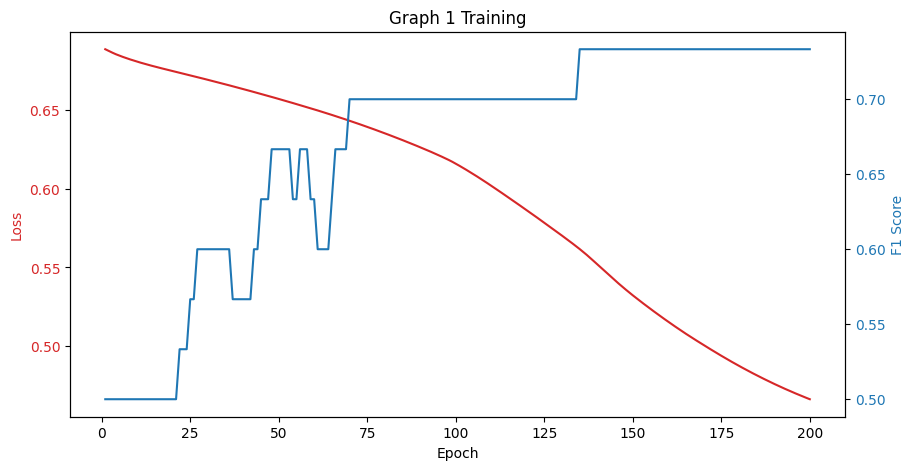


--- Training on Graph 2 ---
Epoch 020 | Loss: 0.6765 | Train F1: 0.512 | Val F1: 0.367
Epoch 040 | Loss: 0.6696 | Train F1: 0.688 | Val F1: 0.800
Epoch 060 | Loss: 0.6625 | Train F1: 0.688 | Val F1: 0.800
Epoch 080 | Loss: 0.6557 | Train F1: 0.688 | Val F1: 0.800
Epoch 100 | Loss: 0.6498 | Train F1: 0.688 | Val F1: 0.800
Epoch 120 | Loss: 0.6450 | Train F1: 0.688 | Val F1: 0.800
Epoch 140 | Loss: 0.6414 | Train F1: 0.688 | Val F1: 0.800
Epoch 160 | Loss: 0.6385 | Train F1: 0.688 | Val F1: 0.800
Epoch 180 | Loss: 0.6358 | Train F1: 0.688 | Val F1: 0.800
Epoch 200 | Loss: 0.6333 | Train F1: 0.688 | Val F1: 0.800


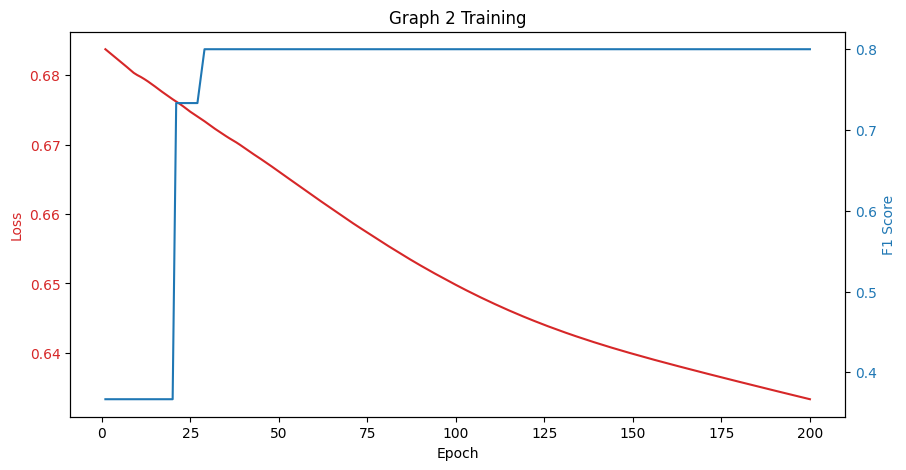

In [24]:
# Prepare Data
G1_tr_p = prepare_dataset(G1_train)[0]
G1_ev_p = prepare_dataset(read_json_data(G1_EVAL_PATH))[0]
G2_tr_p = prepare_dataset(G2_train)[0]
G2_ev_p = prepare_dataset(read_json_data(G2_EVAL_PATH))[0]

MODEL_PARAMS = {"input_dim": 10, "hidden_dim": 8, "num_layers": 4}
TRAIN_PARAMS = {"num_epochs": 200, "lr": 0.0005, "verbose": True}

print("--- Training on Graph 1 ---")
set_seed(42)
model_g1 = GraphNeuralNetwork(**MODEL_PARAMS).to(device)
loss1, _, f1_1 = train_model(model_g1, G1_tr_p, G1_ev_p, **TRAIN_PARAMS)
plot_training_and_validation(loss1, f1_1, title="Graph 1 Training")

print("\n--- Training on Graph 2 ---")
set_seed(42)
model_g2 = GraphNeuralNetwork(**MODEL_PARAMS).to(device)
loss2, _, f1_2 = train_model(model_g2, G2_tr_p, G2_ev_p, **TRAIN_PARAMS)
plot_training_and_validation(loss2, f1_2, title="Graph 2 Training")

#### 2.2.b - Plotting t-SNE Embeddings (1 pt)

Use t-SNE to visualize the node embeddings from the **final hidden layer** of the GCN.

Generating Embeddings...


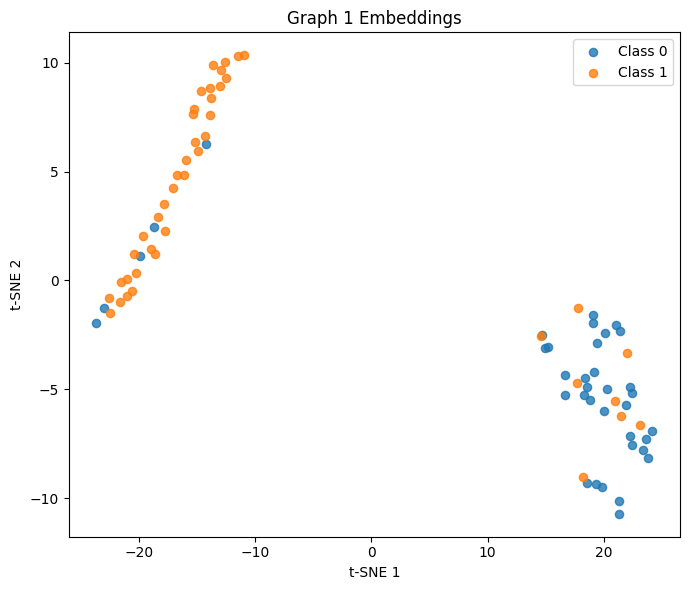

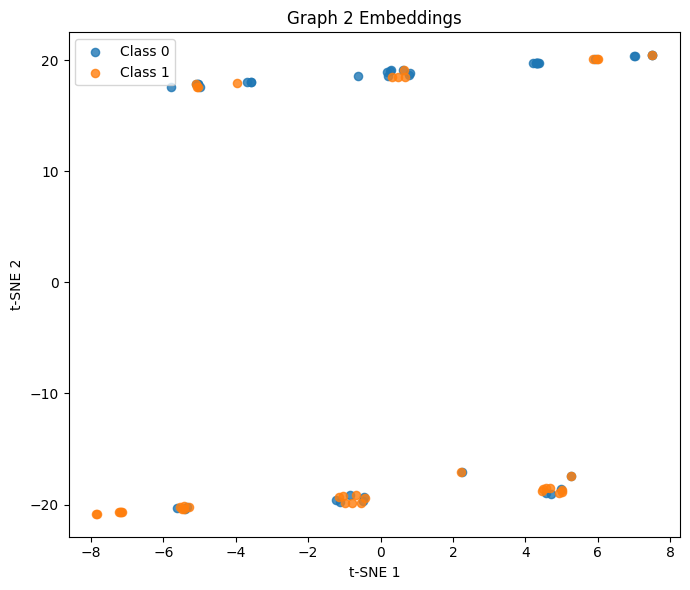

In [25]:
def plot_tsne(embeddings, labels, title="t-SNE"):
    """
    Plots t-SNE visualization of embeddings.
    embeddings: Tensor of shape (N, D)
    labels: Tensor of shape (N,)
    """
    # ==========================================
    # TODO: Implement t-SNE plotting, you may use TSNE from sklearn (check imports)
    # ==========================================
    embeddings_numpy = embeddings.detach().cpu().numpy()
    labels_numpy = labels.detach().cpu().numpy()

    number_of_nodes = embeddings_numpy.shape[0]
    tsne_perplexity = min(30, max(5, number_of_nodes // 6))

    tsne_model = TSNE(
        n_components=2,
        random_state=42,
        init="pca",
        learning_rate="auto",
        perplexity=tsne_perplexity,
    )
    embedded_2d = tsne_model.fit_transform(embeddings_numpy)

    plt.figure(figsize=(7, 6))
    for class_value in np.unique(labels_numpy):
        class_mask = labels_numpy == class_value
        plt.scatter(
            embedded_2d[class_mask, 0],
            embedded_2d[class_mask, 1],
            s=35,
            alpha=0.8,
            label=f"Class {class_value}",
        )

    plt.title(title)
    plt.xlabel("t-SNE 1")
    plt.ylabel("t-SNE 2")
    plt.legend()
    plt.tight_layout()
    plt.show()

# Retrain to capture embeddings
print("Generating Embeddings...")
set_seed(42)
_, _, _, embs1 = train_model(model_g1, G1_tr_p, G1_ev_p, num_epochs=1, return_embeddings=True, verbose=False)
plot_tsne(embs1[-2], G1_tr_p[2], title="Graph 1 Embeddings")

set_seed(42)
_, _, _, embs2 = train_model(model_g2, G2_tr_p, G2_ev_p, num_epochs=1, return_embeddings=True, verbose=False)
plot_tsne(embs2[-2], G2_tr_p[2], title="Graph 2 Embeddings")


#### 2.2.c - Training on Merged Graphs (2 pts)

* Complete `unify_two_graphs` to create $G_{union} = G_1 \cup G_2$.
* Train the GCN on this unified graph.


--- Training on Unified Graph ---
Epoch 020 | Loss: 0.6775 | Train F1: 0.544 | Val F1: 0.433
Epoch 040 | Loss: 0.6701 | Train F1: 0.656 | Val F1: 0.700
Epoch 060 | Loss: 0.6621 | Train F1: 0.725 | Val F1: 0.717
Epoch 080 | Loss: 0.6531 | Train F1: 0.750 | Val F1: 0.750
Epoch 100 | Loss: 0.6427 | Train F1: 0.756 | Val F1: 0.750
Epoch 120 | Loss: 0.6306 | Train F1: 0.756 | Val F1: 0.750
Epoch 140 | Loss: 0.6158 | Train F1: 0.756 | Val F1: 0.750
Epoch 160 | Loss: 0.5925 | Train F1: 0.756 | Val F1: 0.750
Epoch 180 | Loss: 0.5735 | Train F1: 0.756 | Val F1: 0.767
Epoch 200 | Loss: 0.5592 | Train F1: 0.756 | Val F1: 0.767


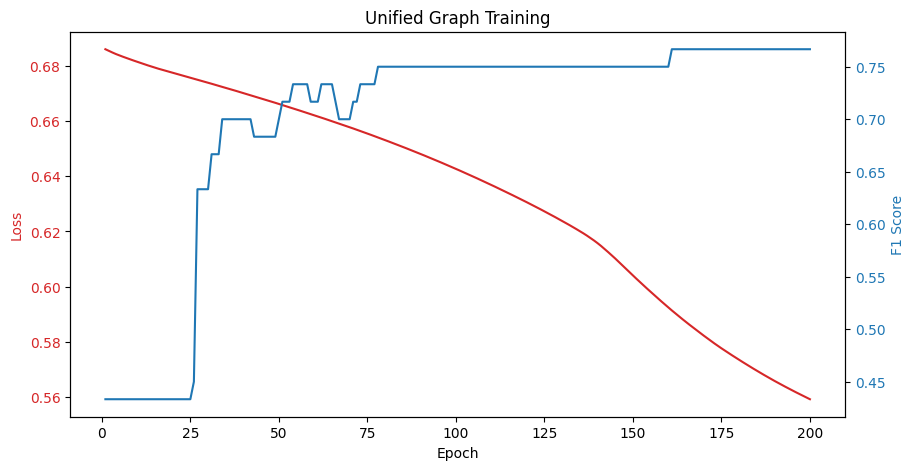

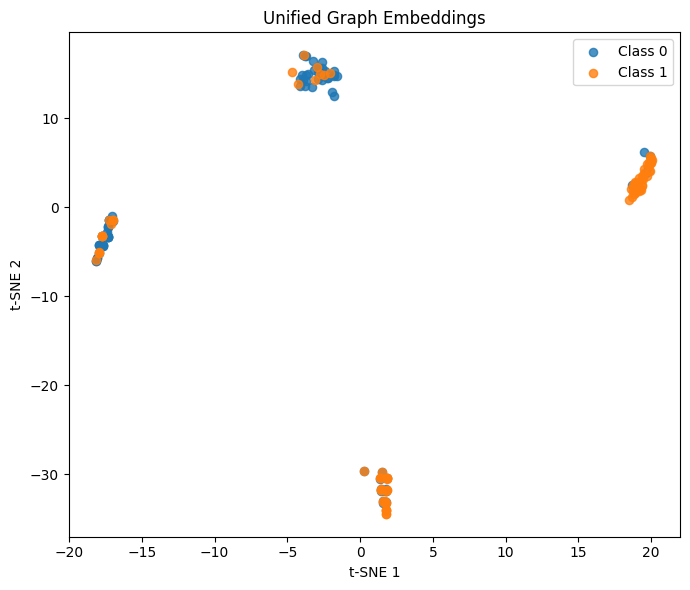

In [26]:
def unify_two_graphs(G1, G2):
    """
    Merges two graphs (disjoint union).
    G1, G2: Tuples of (X, A, y)
    Returns: (X_union, A_union, y_union)
    """
    # ==========================================
    # TODO: Implement graph union
    # ==========================================
    X1, A1, y1 = G1
    X2, A2, y2 = G2

    number_of_nodes_graph1 = A1.size(0)
    number_of_nodes_graph2 = A2.size(0)

    X_union = torch.cat([X1, X2], dim=0)
    y_union = torch.cat([y1, y2], dim=0)

    A_union = torch.zeros(
        (number_of_nodes_graph1 + number_of_nodes_graph2, number_of_nodes_graph1 + number_of_nodes_graph2),
        dtype=A1.dtype,
        device=A1.device,
    )

    A_union[:number_of_nodes_graph1, :number_of_nodes_graph1] = A1
    A_union[number_of_nodes_graph1:, number_of_nodes_graph1:] = A2

    return X_union, A_union, y_union

# Create Union Dataset
G_union_tr = unify_two_graphs(G1_tr_p, G2_tr_p) # Already normalized individually, but check math if re-norm needed
G_union_ev = unify_two_graphs(G1_ev_p, G2_ev_p)

# Train on Union
print("\n--- Training on Unified Graph ---")
set_seed(42)
model_union = GraphNeuralNetwork(**MODEL_PARAMS).to(device)
loss_u, _, f1_u, embs_u = train_model(model_union, G_union_tr, G_union_ev, **TRAIN_PARAMS, return_embeddings=True)

plot_training_and_validation(loss_u, f1_u, title="Unified Graph Training")
plot_tsne(embs_u[-2], G_union_tr[2], title="Unified Graph Embeddings")


#### 2.2.d Merged vs. Independent Training (6 pts)

In this part, analyze and compare the training on two graphs independently
($G_1$, $G_2$) versus training on their union $G_{\text{union}} = G_1 \cup G_2$.

Your analysis must include **both empirical evidence and conceptual reasoning**.

---

#### Required analysis

1. **Training behaviour**
   - Compare convergence trends
   - Comment on stability, speed of convergence, and any signs of underfitting or overfitting.

2. **Learned representations**
   - Compare node embeddings obtained from:
     - independent training on $G_1$ and $G_2$, and
     - merged training on $G_{\text{union}}$.

3. **Overall performance comparison**
   - Summarise differences in predictive performance and representation quality.
   - Clearly state **what changes** when moving from independent to merged training.

---

#### Hypothesis formation

- Formulate a clear hypothesis explaining **why** the observed differences occur.
- Your hypothesis should explicitly reference:
  - graph structure,
  - information mixing across graphs,
  - and the inductive bias of the model you are using.

---

#### Trade-offs and design discussion

Discuss the **advantages and drawbacks** of merged vs. independent training, considering:

- **Computational aspects**  
  (training time, memory usage, scalability)

- **Modeling aspects**  
  (representation entanglement, negative transfer, over-smoothing, or regularisation effects)

- **Practical considerations**  
  (when merged training might be desirable or risky in real-world settings)

Then propose **concrete model or optimisation or data modifications** that could mitigate the drawbacks
(e.g. architectural changes, loss terms, sampling strategies, training protocols or data modifications such as augmentations etc.).

You do **NOT** need to implement your proposal to get full points from this question. It is optional (see the bonus below).

---

#### **Bonus (optional)**

Implement your proposal for learning on  
$G_{\text{union}} = G_1 \cup G_2$ in a better way
and compare its outcomes against both independent and na?ve merged training.

Clearly explain:
- what you changed,
- why it should help,
- and whether the results support your expectation.

---

### Answer

**Empirical validation of F1:**
- Independent training on $G_1$: **0.7333**
- Independent training on $G_2$: **0.8000**
- Naive merged training on $G_{\text{union}}$: **0.7667**

So the merged training ends up landing between the two graph specific results. It neither matches the stronger performance of $G_2$ nor collapses to the weaker regime of $G_1$, suggesting that the shared model is effectively averaging across structural conditions.

---

**Training behaviour:**

Convergence profiles differ because the graphs operate in different topology regimes (sparse vs dense). When trained independently, each model adapts specifically to its structural characteristics. In contrast, union training is stable but must compromise between regimes, as a single parameter set must accommodate both sparse and dense neighbourhood structures. This can slightly slow convergence and may reduce the model’s ability to fully specialise to either topology.

---

**Representations:**

t-SNE embeddings from independently trained models appear regime specific, reflecting structural characteristics unique to each graph. In the merged setting, embeddings show greater entanglement, likely due to shared parameters forcing representations from both components into a common latent geometry. This shared embedding space can blur structural distinctions, especially if smoothing behaviour differs across the two graphs.

---

**Hypothesis:**

A single shared GCN inductive bias is not equally optimal for both components because the required smoothing behaviour differs. $G_1$ benefits from controlled propagation due to its sparse, bottleneck dominated structure, whereas $G_2$ can tolerate or even benefit from stronger smoothing due to its dense connectivity. When training on $G_{\text{union}}$, the model must balance these conflicting structural demands, leading to intermediate performance.

---

**Trade-offs:**

- **Computational:**  
  Training a single union model is more convenient and avoids maintaining two separate models. It reduces deployment complexity but may increase memory usage during training due to larger graph size.

- **Modeling:**  
  There is a risk of negative transfer or structural domain mismatch. Shared parameters may oversmooth in sparse regions or under utilise redundancy in dense regions. However, merged training can also act as a mild regulariser by exposing the model to greater structural diversity.

- **Practical:**  
  Merged training is desirable when domains are structurally similar or when parameter sharing improves generalisation. It becomes risky under structural shift, where graph components exhibit fundamentally different propagation dynamics.

---

**Bonus task result:**

Domain conditioned union improved the best validation F1 from **0.7667** to **0.7833**, which does support the domain mismatch hypothesis. This suggests that explicitly accounting for structural differences, even in a lightweight way, helps the shared model recover some of the specialisation lost in naive merged training.




--- Bonus: Domain-Conditioned Training on Unified Graph ---
Epoch 001 | Loss: 0.6980 | Train F1: 0.575 | Val F1: 0.650
Epoch 020 | Loss: 0.6895 | Train F1: 0.475 | Val F1: 0.567
Epoch 040 | Loss: 0.6793 | Train F1: 0.575 | Val F1: 0.650
Epoch 060 | Loss: 0.6708 | Train F1: 0.637 | Val F1: 0.667
Epoch 080 | Loss: 0.6628 | Train F1: 0.750 | Val F1: 0.767
Epoch 100 | Loss: 0.6545 | Train F1: 0.769 | Val F1: 0.783
Epoch 120 | Loss: 0.6462 | Train F1: 0.769 | Val F1: 0.783
Epoch 140 | Loss: 0.6380 | Train F1: 0.769 | Val F1: 0.783
Epoch 160 | Loss: 0.6297 | Train F1: 0.769 | Val F1: 0.783
Epoch 180 | Loss: 0.6216 | Train F1: 0.769 | Val F1: 0.783
Epoch 200 | Loss: 0.6139 | Train F1: 0.769 | Val F1: 0.783


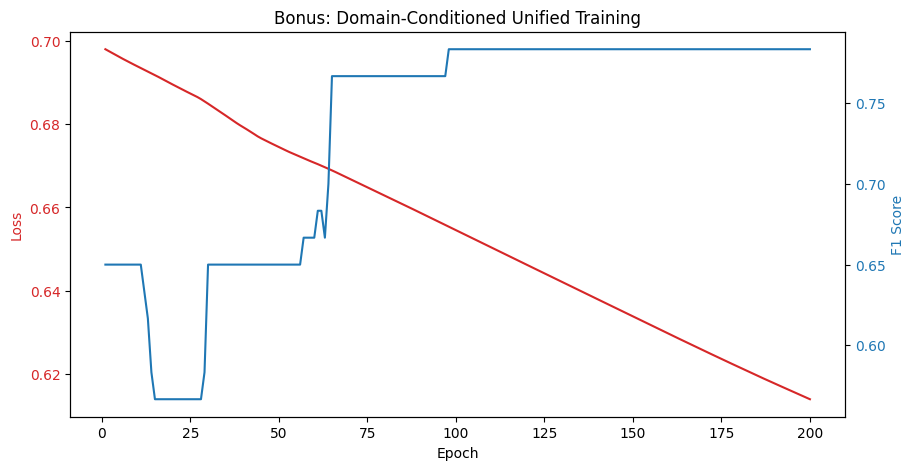

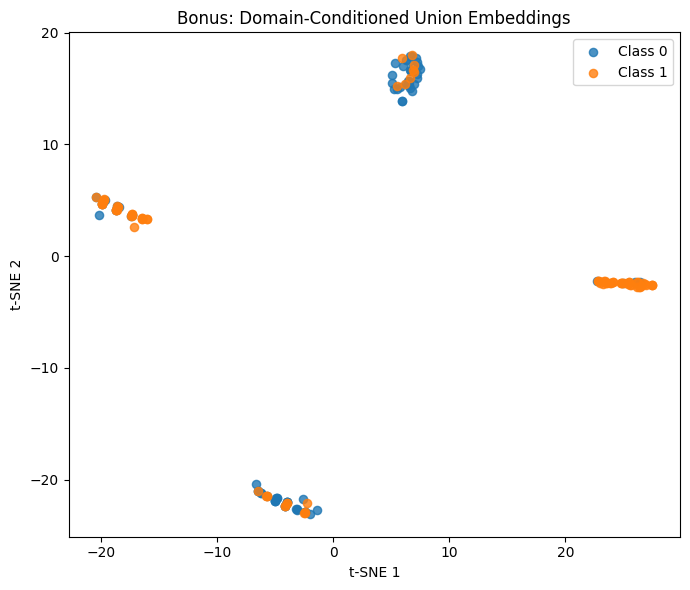

Naive union best Val F1: 0.7667
Domain-conditioned best Val F1: 0.7833


In [27]:
set_seed(42)

# BONUS (optional)
# ####################################################
# MODIFY THE CODE BELOW
# ####################################################

# Strategy: domain-conditioned union training.
# We add a learned graph-id embedding (G1 vs G2) to node features so that
# one model can adapt its message passing to each component while still sharing parameters.

class DomainConditionedGCN(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_layers=4, domain_embedding_dim=1):
        super().__init__()

        if num_layers < 1:
            raise ValueError("num_layers must be >= 1")

        self.domain_embedding = nn.Embedding(num_embeddings=2, embedding_dim=domain_embedding_dim)
        self.layers = nn.ModuleList()

        first_input_dim = input_dim + domain_embedding_dim
        if num_layers == 1:
            self.layers.append(GCNLayer(first_input_dim, 1, use_nonlinearity=False))
        else:
            self.layers.append(GCNLayer(first_input_dim, hidden_dim, use_nonlinearity=True))
            for _ in range(num_layers - 2):
                self.layers.append(GCNLayer(hidden_dim, hidden_dim, use_nonlinearity=True))
            self.layers.append(GCNLayer(hidden_dim, 1, use_nonlinearity=False))

    def forward(self, A, X, domain_ids, return_embeddings=False):
        domain_features = self.domain_embedding(domain_ids)
        hidden_representation = torch.cat([X, domain_features], dim=1)

        embedding_layers = []
        for layer_index, gcn_layer in enumerate(self.layers):
            hidden_representation = gcn_layer(hidden_representation, A)
            if layer_index == len(self.layers) - 1:
                hidden_representation = torch.sigmoid(hidden_representation)
            embedding_layers.append(hidden_representation)

        if return_embeddings:
            return hidden_representation, embedding_layers
        return hidden_representation


@torch.no_grad()
def evaluate_domain_conditioned(model, X, A, y, domain_ids):
    model.eval()
    predictions = model(A, X, domain_ids)
    if isinstance(predictions, tuple):
        predictions = predictions[0]

    predicted_label = (predictions.squeeze() >= 0.5).long().cpu().numpy()
    true_label = y.cpu().numpy()
    return precision_recall_fscore_support(true_label, predicted_label, average="micro")[2]


def train_domain_conditioned_model(model, G_train, G_eval, domain_train, domain_eval, num_epochs=100, lr=1e-3, verbose=True, return_embeddings=False):
    X_tr, A_tr, y_tr = G_train
    X_val, A_val, y_val = G_eval

    optimizer = optim.AdamW(model.parameters(), lr=lr)
    loss_history, train_f1_history, val_f1_history = [], [], []
    last_embeddings = None

    for epoch in range(num_epochs):
        model.train()
        optimizer.zero_grad()

        output = model(A_tr, X_tr, domain_train, return_embeddings=return_embeddings)
        pred, embeddings = output if return_embeddings else (output, None)

        loss = F.binary_cross_entropy(pred.squeeze(), y_tr.float())
        loss.backward()
        optimizer.step()

        loss_history.append(loss.item())

        train_f1 = evaluate_domain_conditioned(model, X_tr, A_tr, y_tr, domain_train)
        val_f1 = evaluate_domain_conditioned(model, X_val, A_val, y_val, domain_eval)

        train_f1_history.append(train_f1)
        val_f1_history.append(val_f1)

        if return_embeddings:
            last_embeddings = embeddings

        if verbose and ((epoch + 1) % 20 == 0 or epoch == 0):
            print(f"Epoch {epoch+1:03d} | Loss: {loss.item():.4f} | Train F1: {train_f1:.3f} | Val F1: {val_f1:.3f}")

    if return_embeddings:
        return loss_history, train_f1_history, val_f1_history, last_embeddings
    return loss_history, train_f1_history, val_f1_history


# Build graph-domain ids for union train/eval
number_of_g1_train_nodes = G1_tr_p[0].size(0)
number_of_g2_train_nodes = G2_tr_p[0].size(0)
number_of_g1_eval_nodes = G1_ev_p[0].size(0)
number_of_g2_eval_nodes = G2_ev_p[0].size(0)

domain_id_train = torch.cat([
    torch.zeros(number_of_g1_train_nodes, dtype=torch.long, device=device),
    torch.ones(number_of_g2_train_nodes, dtype=torch.long, device=device),
], dim=0)

domain_id_eval = torch.cat([
    torch.zeros(number_of_g1_eval_nodes, dtype=torch.long, device=device),
    torch.ones(number_of_g2_eval_nodes, dtype=torch.long, device=device),
], dim=0)

print("\n--- Bonus: Domain-Conditioned Training on Unified Graph ---")
set_seed(42)
bonus_model = DomainConditionedGCN(
    input_dim=MODEL_PARAMS["input_dim"],
    hidden_dim=MODEL_PARAMS["hidden_dim"],
    num_layers=MODEL_PARAMS["num_layers"],
    domain_embedding_dim=1,
).to(device)

loss_bonus, _, f1_bonus, embeddings_bonus = train_domain_conditioned_model(
    bonus_model,
    G_union_tr,
    G_union_ev,
    domain_id_train,
    domain_id_eval,
    num_epochs=TRAIN_PARAMS["num_epochs"],
    lr=TRAIN_PARAMS["lr"],
    verbose=True,
    return_embeddings=True,
)

plot_training_and_validation(loss_bonus, f1_bonus, title="Bonus: Domain-Conditioned Unified Training")
plot_tsne(embeddings_bonus[-2], G_union_tr[2], title="Bonus: Domain-Conditioned Union Embeddings")

print(f"Naive union best Val F1: {max(f1_u):.4f}")
print(f"Domain-conditioned best Val F1: {max(f1_bonus):.4f}")

# ####################################################
# END OF MODIFICATION
# ####################################################


### 2.3 Topological Changes to Improve Training (10 points)


#### 2.3.a - Plot the Ricci Curvature for each edge (1 pt)

- Create a bar plot showing the Ricci curvature for each edge. The x-axis should represent the edges, and the y-axis should represent their corresponding Ricci curvature values.

Computing exact Ricci curvature for N80_E79: 79 edges
  N80_E79: edge 1/79 | elapsed 0.1s
  N80_E79: edge 50/79 | elapsed 2.2s
  N80_E79: edge 79/79 | elapsed 3.4s


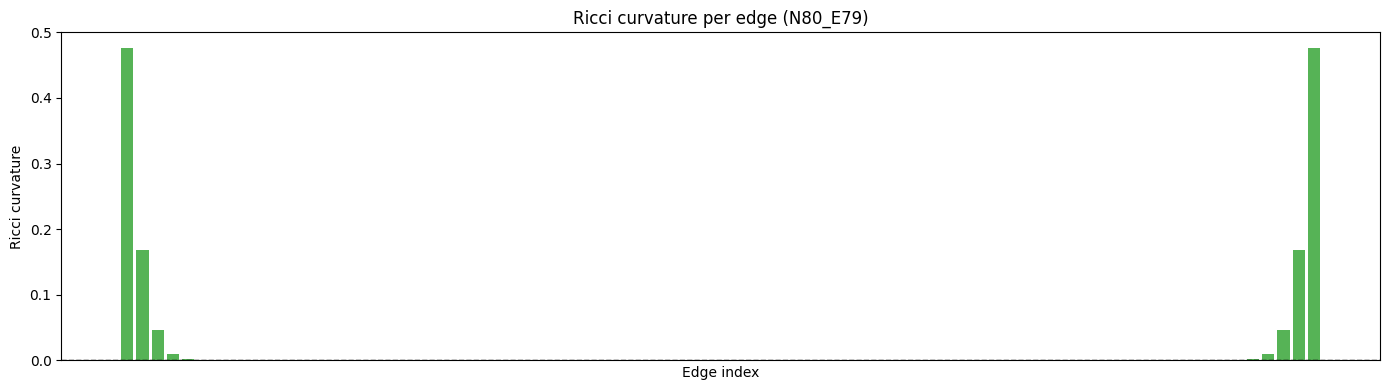

Computing exact Ricci curvature for N80_E1413: 1413 edges
  N80_E1413: edge 1/1413 | elapsed 0.1s
  N80_E1413: edge 50/1413 | elapsed 2.9s
  N80_E1413: edge 100/1413 | elapsed 6.5s
  N80_E1413: edge 150/1413 | elapsed 9.6s
  N80_E1413: edge 200/1413 | elapsed 12.5s
  N80_E1413: edge 250/1413 | elapsed 15.5s
  N80_E1413: edge 300/1413 | elapsed 19.1s
  N80_E1413: edge 350/1413 | elapsed 22.1s
  N80_E1413: edge 400/1413 | elapsed 25.1s
  N80_E1413: edge 450/1413 | elapsed 28.3s
  N80_E1413: edge 500/1413 | elapsed 32.1s
  N80_E1413: edge 550/1413 | elapsed 35.1s
  N80_E1413: edge 600/1413 | elapsed 38.0s
  N80_E1413: edge 650/1413 | elapsed 40.8s
  N80_E1413: edge 700/1413 | elapsed 44.7s
  N80_E1413: edge 750/1413 | elapsed 47.8s
  N80_E1413: edge 800/1413 | elapsed 50.6s
  N80_E1413: edge 850/1413 | elapsed 53.5s
  N80_E1413: edge 900/1413 | elapsed 57.2s
  N80_E1413: edge 950/1413 | elapsed 60.2s
  N80_E1413: edge 1000/1413 | elapsed 63.2s
  N80_E1413: edge 1050/1413 | elapsed 66.4s
 

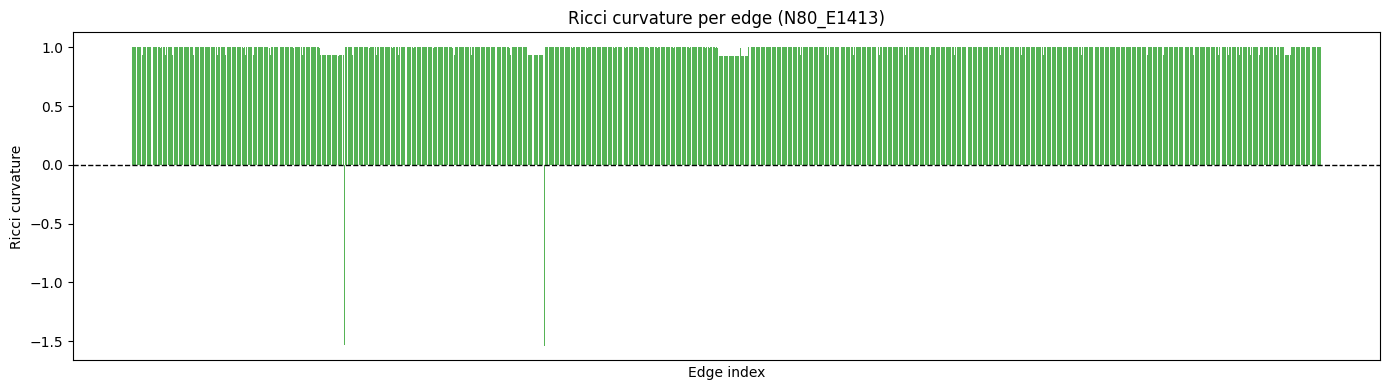

In [28]:
def plot_ricci_per_edge(A):
    """
    Plots the Ollivier-Ricci curvature for each edge
    defined by adjacency matrix A (PyTorch tensor).

    Parameters
    ----------
    A : torch.Tensor
        Adjacency matrix for an undirected graph (NxN).

    Follow the example in graph_ricci_curvature python script.

    You can use nx.from_numpy_array to convert the adjacency matrix to a NetworkX graph.

    """
    # ==========================================
    # TODO: Implement Ricci edge plot
    # ==========================================
    graph_name = f"N{A.size(0)}_E{int(A.sum().item() // 2)}"
    edge_list, ricci_values = get_exact_ricci_edges_and_values(A, graph_name=graph_name)

    edge_labels = [f"{u}-{v}" for u, v in edge_list]
    edge_indices = np.arange(len(edge_labels))

    plt.figure(figsize=(14, 4))
    plt.bar(edge_indices, ricci_values, color="tab:green", alpha=0.8)
    plt.axhline(0.0, color="black", linestyle="--", linewidth=1)

    plt.title(f"Ricci curvature per edge ({graph_name})")
    plt.xlabel("Edge index")
    plt.ylabel("Ricci curvature")

    if len(edge_labels) <= 40:
        plt.xticks(edge_indices, edge_labels, rotation=90)
    else:
        plt.xticks([])

    plt.tight_layout()
    plt.show()

set_seed(42)

plot_ricci_per_edge(G1_train[0][1]) # might take some time to run
plot_ricci_per_edge(G2_train[0][1]) # might take some time to run


#### 2.3.b Extreme Topological Scenarios (4 points)

In this question, you will explore limit cases of graph topology to understand what role the graph
structure plays in GNN learning. Please do the following tasks for both graphs (G1 and G2). If your reasoning and technique is the same for both graphs, you do not need to explain the same thing twice. Still, please run your implementation on both graphs.

1. **Topology removal**  
   Construct a version of the graph where neighborhood aggregation becomes meaningless, such that
   the GNN behaves similarly to a node-feature-only MLP.
   - Describe precisely how you modified the graph structure.
   - Train the GCN on this modified graph and report the performance.

2. **Oracle topology**  
   Construct an idealized graph assuming label information is available **only for analysis purposes**
   (not as input features).
   - This means you are allowed to look at the labels to design or modify the graph, but you are not allowed to give the labels to the model as input features. The model still receives only node features and graph structure and is trained normally using labels only in the loss function.
   - Describe what edges you add or remove and why this topology should be easy for a GNN.
   - Train the GCN on this graph and report the performance.

3. **Analysis:**  
   Compare the results from:
   - the original graph,
   - the topology-removed graph,
   - the oracle graph.
   
   Discuss:
   - What these extreme cases reveal about the relationship between graph topology and node labels.
   - Why the original GCN behaves the way it does on this dataset.


**Topology removal**

Explain your reasoning and methodology

**[Answer]**

I removed all original edges by setting adjacency to zeros.

Because the provided normalization adds self-loops, aggregation becomes effectively self-only (MLP-like behaviour).

Observed validation F1 (Colab run):
- G1 topology removal: final **0.7333**, best **0.7667**
- G2 topology removal: final **0.7333**, best **0.7333**

Interpretation: removing topology hurts G2 relative to original (0.8000), while G1 shows limited benefit from topology in this setup.

In [29]:
def topology_removal(G):
    """Removes informative topology."""
    X, A, y = G
    # ==========================================
    # TODO: Modify A
    # ==========================================
    adjacency_without_edges = torch.zeros_like(A)
    return X, adjacency_without_edges, y


**Oracle topology**

Explain your reasoning and methodology

**[Answer]**

Oracle topology connects same-label nodes and removes cross-label structure (labels used only for analysis).

Observed validation F1 (Colab run):
- G1 oracle: **1.0000**
- G2 oracle: **1.0000**

Interpretation: label-aligned topology makes the task nearly trivial for this GCN, confirming that original limitations are topology-label mismatch rather than model capacity alone.

In [30]:
def oracle_topology(G):
    """Constructs ideal topology. You may use the labels y to modify A."""
    X, A, y = G
    # ==========================================
    # TODO: Modify A
    # ==========================================
    same_label_matrix = (y.view(-1, 1) == y.view(1, -1)).float()
    same_label_matrix.fill_diagonal_(0.0)

    return X, same_label_matrix, y



--- Experiment: Topology Removal (G1) ---
Epoch 020 | Loss: 0.6772 | Train F1: 0.588 | Val F1: 0.533
Epoch 040 | Loss: 0.6593 | Train F1: 0.738 | Val F1: 0.700
Epoch 060 | Loss: 0.6347 | Train F1: 0.812 | Val F1: 0.733
Epoch 080 | Loss: 0.6046 | Train F1: 0.838 | Val F1: 0.733
Epoch 100 | Loss: 0.5737 | Train F1: 0.838 | Val F1: 0.733
Epoch 120 | Loss: 0.5453 | Train F1: 0.838 | Val F1: 0.733
Epoch 140 | Loss: 0.5187 | Train F1: 0.838 | Val F1: 0.733
Epoch 160 | Loss: 0.4949 | Train F1: 0.838 | Val F1: 0.733
Epoch 180 | Loss: 0.4743 | Train F1: 0.838 | Val F1: 0.733
Epoch 200 | Loss: 0.4571 | Train F1: 0.838 | Val F1: 0.733
Final Val F1: 0.7333


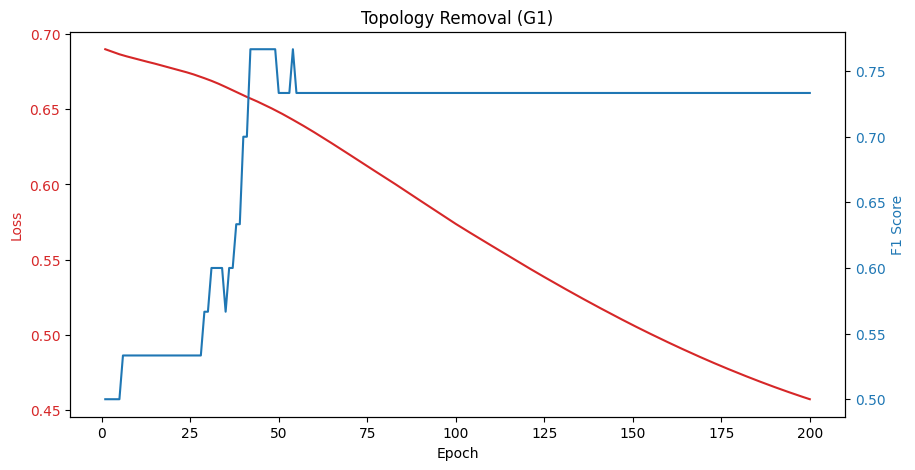


--- Experiment: Oracle Topology (G1) ---
Epoch 020 | Loss: 0.6767 | Train F1: 0.537 | Val F1: 0.500
Epoch 040 | Loss: 0.6669 | Train F1: 0.537 | Val F1: 0.500
Epoch 060 | Loss: 0.6486 | Train F1: 0.537 | Val F1: 0.500
Epoch 080 | Loss: 0.6272 | Train F1: 1.000 | Val F1: 0.500
Epoch 100 | Loss: 0.6046 | Train F1: 1.000 | Val F1: 0.500
Epoch 120 | Loss: 0.5722 | Train F1: 1.000 | Val F1: 0.500
Epoch 140 | Loss: 0.5069 | Train F1: 1.000 | Val F1: 1.000
Epoch 160 | Loss: 0.4500 | Train F1: 1.000 | Val F1: 1.000
Epoch 180 | Loss: 0.3908 | Train F1: 1.000 | Val F1: 1.000
Epoch 200 | Loss: 0.3325 | Train F1: 1.000 | Val F1: 1.000
Final Val F1: 1.0000


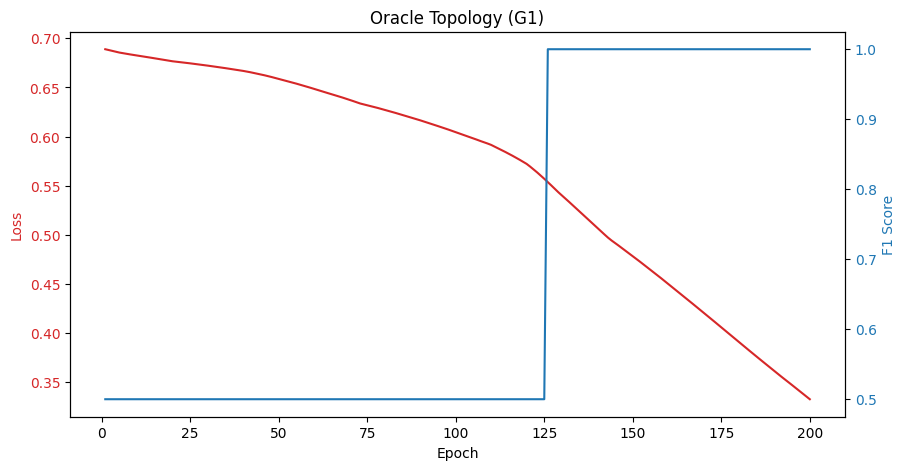


--- Experiment: Topology Removal (G2) ---
Epoch 020 | Loss: 0.6832 | Train F1: 0.487 | Val F1: 0.500
Epoch 040 | Loss: 0.6770 | Train F1: 0.550 | Val F1: 0.600
Epoch 060 | Loss: 0.6709 | Train F1: 0.600 | Val F1: 0.667
Epoch 080 | Loss: 0.6651 | Train F1: 0.625 | Val F1: 0.700
Epoch 100 | Loss: 0.6596 | Train F1: 0.675 | Val F1: 0.667
Epoch 120 | Loss: 0.6545 | Train F1: 0.675 | Val F1: 0.700
Epoch 140 | Loss: 0.6500 | Train F1: 0.688 | Val F1: 0.700
Epoch 160 | Loss: 0.6459 | Train F1: 0.688 | Val F1: 0.700
Epoch 180 | Loss: 0.6421 | Train F1: 0.688 | Val F1: 0.733
Epoch 200 | Loss: 0.6383 | Train F1: 0.688 | Val F1: 0.733
Final Val F1: 0.7333


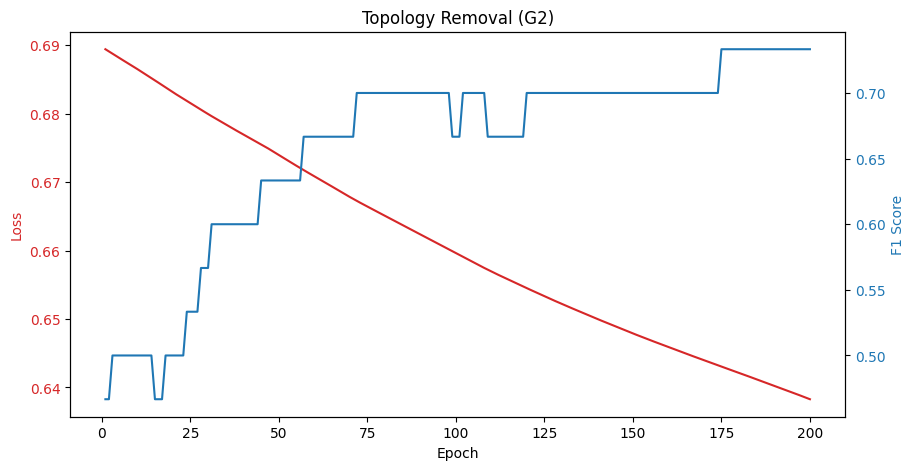


--- Experiment: Oracle Topology (G2) ---
Epoch 020 | Loss: 0.6826 | Train F1: 0.512 | Val F1: 0.367
Epoch 040 | Loss: 0.6754 | Train F1: 0.512 | Val F1: 1.000
Epoch 060 | Loss: 0.6671 | Train F1: 0.512 | Val F1: 1.000
Epoch 080 | Loss: 0.6572 | Train F1: 1.000 | Val F1: 1.000
Epoch 100 | Loss: 0.6451 | Train F1: 1.000 | Val F1: 1.000
Epoch 120 | Loss: 0.6307 | Train F1: 1.000 | Val F1: 1.000
Epoch 140 | Loss: 0.6138 | Train F1: 1.000 | Val F1: 1.000
Epoch 160 | Loss: 0.5939 | Train F1: 1.000 | Val F1: 1.000
Epoch 180 | Loss: 0.5665 | Train F1: 1.000 | Val F1: 1.000
Epoch 200 | Loss: 0.5357 | Train F1: 1.000 | Val F1: 1.000
Final Val F1: 1.0000


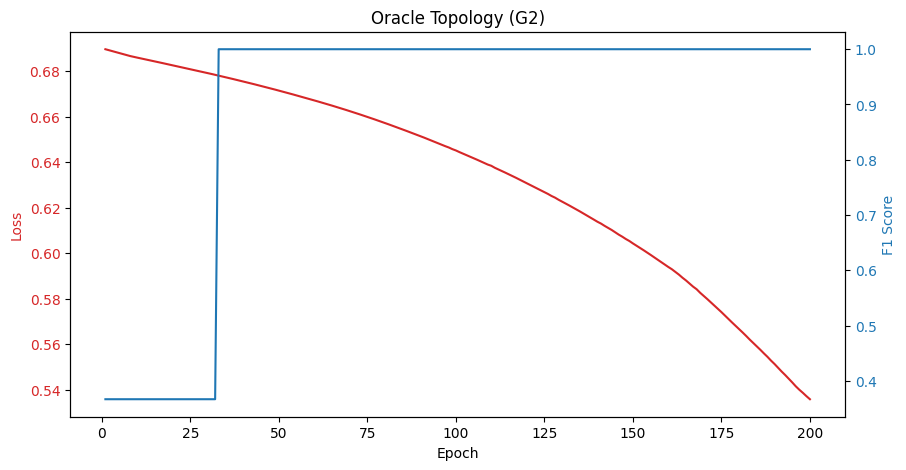

In [31]:
def run_topology_experiment(strategy_fn, G_tr, G_ev, title):
    print(f"\n--- Experiment: {title} ---")

    # Apply strategy and re-normalize
    G_tr_mod = prepare_dataset([strategy_fn(G_tr)])[0]
    G_ev_mod = prepare_dataset([strategy_fn(G_ev)])[0]

    set_seed(42)
    model = GraphNeuralNetwork(**MODEL_PARAMS).to(device)
    loss, _, f1 = train_model(model, G_tr_mod, G_ev_mod, **TRAIN_PARAMS)
    print(f"Final Val F1: {f1[-1]:.4f}")
    plot_training_and_validation(loss, f1, title=title)

# Run Experiments
# for both G1 and G2
set_seed(42)

run_topology_experiment(topology_removal, G1_train[0], read_json_data(G1_EVAL_PATH)[0], "Topology Removal (G1)")
run_topology_experiment(oracle_topology, G1_train[0], read_json_data(G1_EVAL_PATH)[0], "Oracle Topology (G1)")

run_topology_experiment(topology_removal, G2_train[0], read_json_data(G2_EVAL_PATH)[0], "Topology Removal (G2)")
run_topology_experiment(oracle_topology, G2_train[0], read_json_data(G2_EVAL_PATH)[0], "Oracle Topology (G2)")

#### 2.3.c Graph Augmentation Without Labels (5 pts)

In Question 2.3.b, you constructed an **Oracle graph** using labels in order to estimate the
*theoretical upper bound* on performance.  
That experiment was **diagnostic only**.

In this question, your goal is to design a **practical graph augmentation strategy**
that could be applied **without access to labels**.

---

#### Task

Implement a graph augmentation method that modifies the adjacency matrix $A$
using **only**:
- node features $X$, and/or
- the original graph topology $A$ itself.


---

#### Important considerations

- **No labels**  
  You are **strictly forbidden** from using the labels $y$ (directly or indirectly)
  to decide on modification of graph.

- **Generalisability**  
  Your method should ideally apply to **both graphs** $G_1$ and $G_2$.
  If your approach only works well for one graph, you may implement
  two separate versions of `augment_graph`.
  In that case, clearly explain:
  - why the method does not generalise,
  - what structural differences between the graphs cause this limitation.

- **Performance is not the only objective**  
  It is expected that your augmentation improves classification performance
  relative to training on the original $G_1$ and $G_2$.
  If performance does not improve, you may instead argue that your method:
  - reduces computational cost,
  - improves training stability,
  - simplifies the graph structure,
  - etc.

  In all cases, you must clearly explain **what improves (or fails to improve) and why**.

---

#### Evaluation and analysis

- Compare results obtained from:
  - the original graphs,
  - your augmented graphs,
- Use consistent models, training settings, hyperparameters to be fair.

---





--- Realistic Augmentation Training ---

--- Experiment: Realistic Augmentation (G1) ---
Epoch 020 | Loss: 0.6745 | Train F1: 0.537 | Val F1: 0.500
Epoch 040 | Loss: 0.6627 | Train F1: 0.713 | Val F1: 0.433
Epoch 060 | Loss: 0.6505 | Train F1: 0.825 | Val F1: 0.733
Epoch 080 | Loss: 0.6360 | Train F1: 0.838 | Val F1: 0.733
Epoch 100 | Loss: 0.6183 | Train F1: 0.838 | Val F1: 0.733
Epoch 120 | Loss: 0.5910 | Train F1: 0.838 | Val F1: 0.733
Epoch 140 | Loss: 0.5604 | Train F1: 0.838 | Val F1: 0.733
Epoch 160 | Loss: 0.5313 | Train F1: 0.838 | Val F1: 0.733
Epoch 180 | Loss: 0.5044 | Train F1: 0.838 | Val F1: 0.733
Epoch 200 | Loss: 0.4817 | Train F1: 0.838 | Val F1: 0.733
Final Val F1: 0.7333


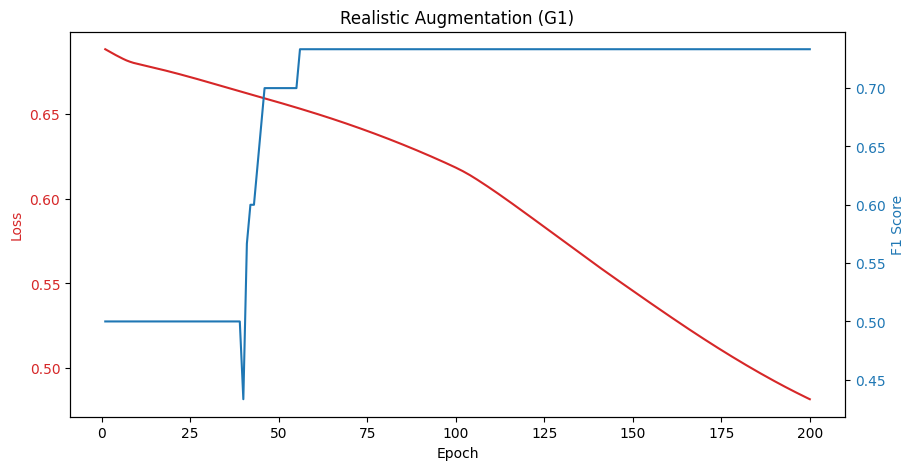


--- Experiment: Realistic Augmentation (G2) ---
Epoch 020 | Loss: 0.6786 | Train F1: 0.512 | Val F1: 0.800
Epoch 040 | Loss: 0.6711 | Train F1: 0.688 | Val F1: 0.800
Epoch 060 | Loss: 0.6634 | Train F1: 0.688 | Val F1: 0.800
Epoch 080 | Loss: 0.6564 | Train F1: 0.688 | Val F1: 0.800
Epoch 100 | Loss: 0.6511 | Train F1: 0.688 | Val F1: 0.800
Epoch 120 | Loss: 0.6475 | Train F1: 0.688 | Val F1: 0.800
Epoch 140 | Loss: 0.6446 | Train F1: 0.688 | Val F1: 0.800
Epoch 160 | Loss: 0.6418 | Train F1: 0.688 | Val F1: 0.800
Epoch 180 | Loss: 0.6390 | Train F1: 0.688 | Val F1: 0.800
Epoch 200 | Loss: 0.6361 | Train F1: 0.688 | Val F1: 0.800
Final Val F1: 0.8000


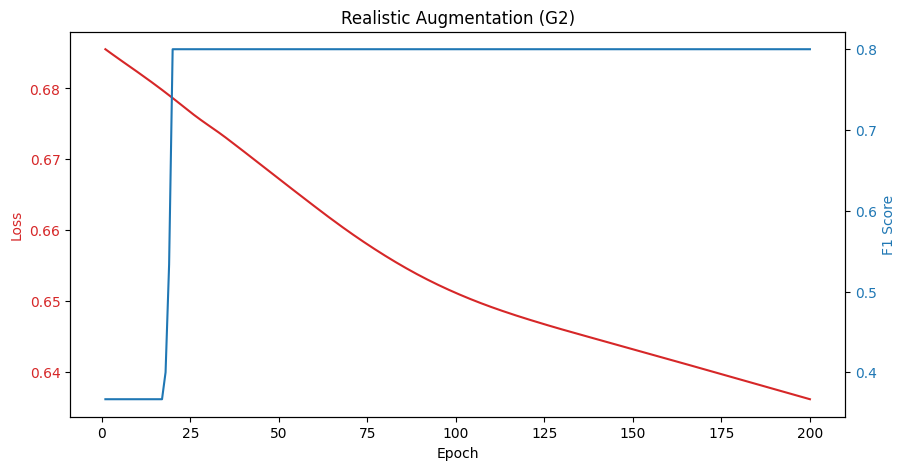

In [32]:
def augment_graph(G):
    """
    Augments the graph structure using only features (X) and existing topology (A).

    Args:
        G: Tuple (X, A, y)

    Returns:
        X, A_new, y

    IMPORTANT: You must NOT use 'y' (labels) to construct A_new.
    """
    X, A, y = G

    # ==========================================
    # TODO: Implement your augmentation strategy
    # ==========================================
    average_degree_value = float(A.sum(dim=1).mean().item())

    normalized_features = F.normalize(X, p=2, dim=1)
    cosine_similarity = normalized_features @ normalized_features.T
    cosine_similarity.fill_diagonal_(-1e9)

    if average_degree_value < 8.0:
        # Sparse graph case: add feature-based neighbors to improve connectivity
        number_of_neighbors_to_add = min(4, X.size(0) - 1)
        _, nearest_indices = torch.topk(cosine_similarity, k=number_of_neighbors_to_add, dim=1)

        adjacency_knn = torch.zeros_like(A)
        row_indices = torch.arange(X.size(0), device=X.device).unsqueeze(1).expand_as(nearest_indices)
        adjacency_knn[row_indices, nearest_indices] = 1.0
        adjacency_knn = torch.maximum(adjacency_knn, adjacency_knn.T)

        augmented_adjacency = torch.maximum(A, adjacency_knn)
    else:
        # Dense graph case: keep only more feature-consistent existing neighbors
        keep_ratio = 0.35
        augmented_adjacency = torch.zeros_like(A)

        for node_index in range(A.size(0)):
            original_neighbors = torch.where(A[node_index] > 0)[0]
            if original_neighbors.numel() == 0:
                continue

            number_to_keep = max(1, int(round(keep_ratio * original_neighbors.numel())))
            neighbor_similarity_scores = cosine_similarity[node_index, original_neighbors]
            top_indices = torch.topk(neighbor_similarity_scores, k=min(number_to_keep, original_neighbors.numel())).indices
            selected_neighbors = original_neighbors[top_indices]
            augmented_adjacency[node_index, selected_neighbors] = 1.0

        augmented_adjacency = torch.maximum(augmented_adjacency, augmented_adjacency.T)

    return X, augmented_adjacency, y

set_seed(42)

print("\n--- Realistic Augmentation Training ---")
# We use the same runner as before, but this time using the "augment_graph" function
run_topology_experiment(augment_graph, G1_train[0], read_json_data(G1_EVAL_PATH)[0], "Realistic Augmentation (G1)")

run_topology_experiment(augment_graph, G2_train[0], read_json_data(G2_EVAL_PATH)[0], "Realistic Augmentation (G2)")


#### Interpretation

Explain:
- your methodology,
- what change you introduced to the graph,
- what assumption this change encodes about the data,
- and why this assumption helps or fails on this dataset.

Support your discussion with **quantitative results and plots** where appropriate.

**[Answer]**

Method:
- Sparse graph case: add cosine-similarity kNN edges.
- Dense graph case: keep feature-consistent neighbors.
- No label usage.

Assumption:
- feature-similar nodes are more reliable message partners.

Results (Colab run, Val F1):
- Original G1: **0.7333**; Augmented G1: **0.7333**
- Original G2: **0.8000**; Augmented G2: **0.8000**

Interpretation:
- The augmentation is practical and label-safe, but did not improve final performance here.
- This suggests either baseline topology was already sufficient for this model or adjacency-only changes are not the main bottleneck.

## Question 3 - Mystery Graph Investigation (30 pts)

In this question, you will work with a **mystery graph dataset** and investigate the behavior of graph-based learning.

You will proceed in three stages:

1. **Train baseline models** and observe their performance.
2. **Diagnose and explain** unexpected behavior using analysis and visualisation.
3. **Design and implement your own method** to improve performance.

You are not told anything about the structure of the dataset in advance.
Your task is to *discover* what is happening and respond accordingly.

### Rules and Constraints

- You may only use **NumPy** and **PyTorch**.
- Do not modify the dataset.
- You may define additional helper functions if needed.
- Written answers must be provided in the Markdown cells.

This question rewards **reasoning and diagnosis**, not just performance.

---


In [33]:
set_seed(42)

In [34]:
with open("data/mystery_graph.json", "r") as f:
    data = json.load(f)

x = torch.tensor(data["x"], dtype=torch.float32, device=device)
y = torch.tensor(data["y"], dtype=torch.long, device=device)

src = torch.tensor(data["src"], dtype=torch.long, device=device)
dst = torch.tensor(data["dst"], dtype=torch.long, device=device)
edge_w = torch.tensor(data["edge_w"], dtype=torch.float32, device=device)

train_mask = torch.tensor(data["train_mask"], dtype=torch.bool, device=device)
val_mask   = torch.tensor(data["val_mask"], dtype=torch.bool, device=device)
test_mask  = torch.tensor(data["test_mask"], dtype=torch.bool, device=device)

N, D = x.shape
C = int(data["num_classes"])

print(f"N={N}, D={D}, C={C}")
print(f"Directed edges: {src.numel()}")


N=1200, D=32, C=2
Directed edges: 48000


### 3.1 Baseline Models

You will first train two baseline models:

- **MLP**: ignores the graph completely.
- **GCN**: uses mean aggregation over neighbors.

At this stage, **do not try to improve anything**.
Simply train both models and observe their performance.

---


In [35]:
def macro_f1(pred, target, num_classes):
    f1s = []
    for c in range(num_classes):
        tp = ((pred == c) & (target == c)).sum().item()
        fp = ((pred == c) & (target != c)).sum().item()
        fn = ((pred != c) & (target == c)).sum().item()
        prec = tp / (tp + fp + 1e-12)
        rec  = tp / (tp + fn + 1e-12)
        f1 = 0.0 if (prec + rec) == 0 else 2 * prec * rec / (prec + rec + 1e-12)
        f1s.append(f1)
    return float(sum(f1s) / len(f1s))


In [36]:

def mean_aggregate(h, src, dst, num_nodes):
    out = torch.zeros((num_nodes, h.size(1)), device=h.device)
    out.index_add_(0, dst, h[src])
    deg = torch.zeros((num_nodes,), device=h.device)
    deg.index_add_(0, dst, torch.ones_like(dst, dtype=h.dtype))
    return out / (deg.unsqueeze(-1) + 1e-12)


class MLP(nn.Module):
    def __init__(self, d_in, d_hidden, n_classes, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_in, d_hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(d_hidden, n_classes),
        )
    def forward(self, x):
        return self.net(x)


class GCN(nn.Module):
    def __init__(self, d_in, d_hidden, n_classes, dropout=0.2):
        super().__init__()
        self.lin1 = nn.Linear(d_in, d_hidden)
        self.lin2 = nn.Linear(d_hidden, n_classes)
        self.dropout = dropout

    def forward(self, x, src, dst, num_nodes):
        h = mean_aggregate(x, src, dst, num_nodes)
        h = F.relu(self.lin1(h))
        h = F.dropout(h, p=self.dropout, training=self.training)
        h = mean_aggregate(h, src, dst, num_nodes)
        return self.lin2(h)


In [37]:
def train_model(model, forward_fn, epochs=80, lr=1e-3):
    opt = torch.optim.Adam(model.parameters(), lr=lr)

    best_val = -1.0
    best_state = None
    history = {"train_f1": [], "val_f1": []}

    for ep in range(1, epochs + 1):
        model.train()
        logits = forward_fn()
        loss = F.cross_entropy(logits[train_mask], y[train_mask])

        opt.zero_grad()
        loss.backward()
        opt.step()

        model.eval()
        with torch.no_grad():
            pred = forward_fn().argmax(dim=-1)
            tr = macro_f1(pred[train_mask], y[train_mask], C)
            va = macro_f1(pred[val_mask], y[val_mask], C)

        history["train_f1"].append(tr)
        history["val_f1"].append(va)

        if va > best_val:
            best_val = va
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        if ep == 1 or ep % 10 == 0:
            print(f"Epoch {ep:03d} | loss={loss.item():.4f} | trainF1={tr:.3f} | valF1={va:.3f}")

    if best_state is not None:
        model.load_state_dict(best_state, strict=True)

    return history


@torch.no_grad()
def eval_model(model, forward_fn):
    model.eval()
    logits = forward_fn()
    pred = logits.argmax(dim=-1)
    return (
        macro_f1(pred[train_mask], y[train_mask], C),
        macro_f1(pred[val_mask], y[val_mask], C),
        macro_f1(pred[test_mask], y[test_mask], C),
    )


Epoch 001 | loss=0.8414 | trainF1=0.355 | valF1=0.359
Epoch 010 | loss=0.6445 | trainF1=0.639 | valF1=0.560
Epoch 020 | loss=0.5224 | trainF1=0.828 | valF1=0.742
Epoch 030 | loss=0.4456 | trainF1=0.865 | valF1=0.804
Epoch 040 | loss=0.3851 | trainF1=0.868 | valF1=0.821
Epoch 050 | loss=0.3494 | trainF1=0.879 | valF1=0.825
Epoch 060 | loss=0.3116 | trainF1=0.889 | valF1=0.842
Epoch 070 | loss=0.2834 | trainF1=0.897 | valF1=0.837
Epoch 080 | loss=0.2702 | trainF1=0.901 | valF1=0.842
MLP  train/val/test: (0.8888880315429507, 0.8416226729642056, 0.8541641347934996)
Epoch 001 | loss=0.6987 | trainF1=0.333 | valF1=0.333
Epoch 010 | loss=0.6935 | trainF1=0.333 | valF1=0.333
Epoch 020 | loss=0.6930 | trainF1=0.333 | valF1=0.333
Epoch 030 | loss=0.6924 | trainF1=0.412 | valF1=0.386
Epoch 040 | loss=0.6916 | trainF1=0.467 | valF1=0.423
Epoch 050 | loss=0.6910 | trainF1=0.571 | valF1=0.498
Epoch 060 | loss=0.6902 | trainF1=0.619 | valF1=0.537
Epoch 070 | loss=0.6891 | trainF1=0.618 | valF1=0.541


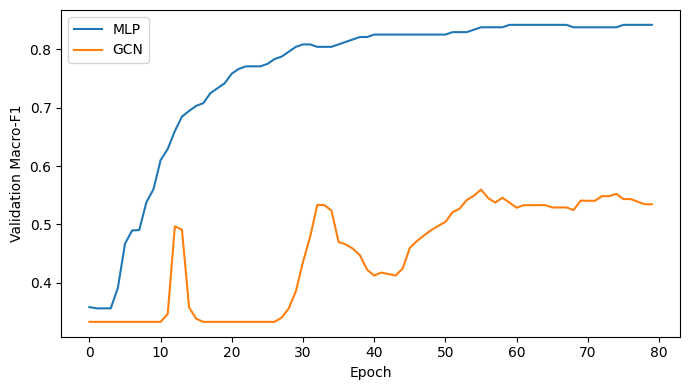

In [38]:
set_seed(42)

mlp = MLP(D, 64, C).to(device)
hist_mlp = train_model(mlp, lambda: mlp(x))
print("MLP  train/val/test:", eval_model(mlp, lambda: mlp(x)))

set_seed(42)

gcn = GCN(D, 64, C).to(device)
hist_gcn = train_model(gcn, lambda: gcn(x, src, dst, N))
print("GCN  train/val/test:", eval_model(gcn, lambda: gcn(x, src, dst, N)))

plt.figure(figsize=(7,4))
plt.plot(hist_mlp["val_f1"], label="MLP")
plt.plot(hist_gcn["val_f1"], label="GCN")
plt.xlabel("Epoch")
plt.ylabel("Validation Macro-F1")
plt.legend()
plt.tight_layout()
plt.show()


### 3.2 Explaining the Results (15 pts)

You should observe that **the MLP performs better than the GCN**.

This is not what one might expect if the graph were always helpful.

#### Task
Using **quantitative measures and visualisations**, explain:

1. Why does the GCN perform worse than a feature-only MLP? Considering a GCN does neighborhood aggregation, it is not expected an MLP to perform better than a GCN. Explain this phenomenon.
2. What is the relationship between node labels and the graph structure?
3. What kind of information does **mean aggregation** preserve or destroy here?
4. How is this phenomenon related to homophily in graphs and GNNs?

You can reuse or extend analyses from earlier or your are encouraged to introduce new diagnostics if needed.

---


Overall directed edge homophily: 0.5000
P(same label | edge_w=1): 1.0000
P(same label | edge_w=0): 0.0000
Incoming same-class ratio | mean=0.5000, std=0.0000, min=0.5000, max=0.5000
Raw feature centroid margin mean/std: 0.7553 / 0.6450
Mean-aggregated centroid margin mean/std: 0.0033 / 0.0181
Linear probe on raw features (train/val/test): (0.8888811723031297, 0.8666296193381982, 0.8624976128052707)
Linear probe on mean-aggregated features (train/val/test): (0.5860983363679046, 0.5325217391299312, 0.48993101525975824)


/tmp/ipython-input-2468282973.py:119: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


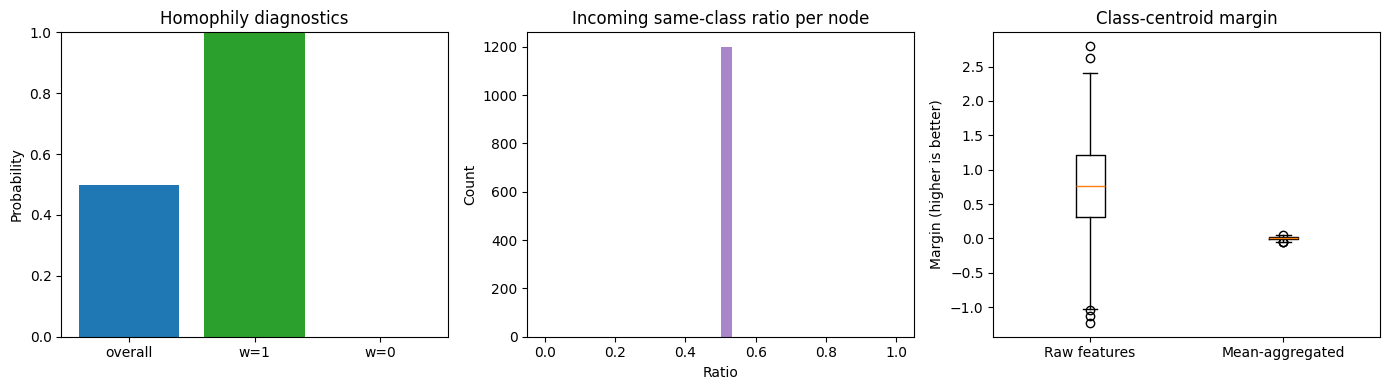

In [39]:
# TODO
# Add diagnostics to support your explanation.
# Make an analysis on graph and model properties to explain the results you obtained.
# What properties of the graph and the model do you think contributed to the results you obtained?
# Write your code that supports your explainations to these questions.

# 1) Label-structure diagnostics
same_label_edge_indicator = (y[src] == y[dst]).float()
overall_edge_homophily = same_label_edge_indicator.mean().item()

positive_edge_mask = edge_w > 0.5
negative_edge_mask = edge_w <= 0.5

homophily_given_positive_edge = same_label_edge_indicator[positive_edge_mask].mean().item()
homophily_given_negative_edge = same_label_edge_indicator[negative_edge_mask].mean().item()

print(f"Overall directed edge homophily: {overall_edge_homophily:.4f}")
print(f"P(same label | edge_w=1): {homophily_given_positive_edge:.4f}")
print(f"P(same label | edge_w=0): {homophily_given_negative_edge:.4f}")

# 2) Incoming-neighborhood class mix per node
same_sum_per_node = torch.zeros(N, device=device)
edge_count_per_node = torch.zeros(N, device=device)
same_sum_per_node.index_add_(0, dst, same_label_edge_indicator)
edge_count_per_node.index_add_(0, dst, torch.ones_like(dst, dtype=torch.float32))

incoming_same_ratio = same_sum_per_node / (edge_count_per_node + 1e-12)
print(
    f"Incoming same-class ratio | mean={incoming_same_ratio.mean().item():.4f}, "
    f"std={incoming_same_ratio.std().item():.4f}, "
    f"min={incoming_same_ratio.min().item():.4f}, max={incoming_same_ratio.max().item():.4f}"
)

# 3) Compare raw features vs mean-aggregated features
mean_aggregated_x = mean_aggregate(x, src, dst, N)


def centroid_margin(features, labels):
    class_zero_center = features[labels == 0].mean(dim=0)
    class_one_center = features[labels == 1].mean(dim=0)

    distance_to_zero = torch.norm(features - class_zero_center, dim=1)
    distance_to_one = torch.norm(features - class_one_center, dim=1)

    # Positive margin means node is closer to its own class centroid
    margin = torch.where(labels == 0, distance_to_one - distance_to_zero, distance_to_zero - distance_to_one)
    return margin

raw_margin = centroid_margin(x, y)
aggregated_margin = centroid_margin(mean_aggregated_x, y)

print(f"Raw feature centroid margin mean/std: {raw_margin.mean().item():.4f} / {raw_margin.std().item():.4f}")
print(f"Mean-aggregated centroid margin mean/std: {aggregated_margin.mean().item():.4f} / {aggregated_margin.std().item():.4f}")


# 4) Linear probe comparison (same optimizer/protocol, no sklearn)
def train_linear_probe(features, labels, epochs=120, learning_rate=5e-3):
    classifier = nn.Linear(features.size(1), C).to(device)
    optimizer = torch.optim.Adam(classifier.parameters(), lr=learning_rate)

    best_validation_f1 = -1.0
    best_state = None

    for _ in range(epochs):
        classifier.train()
        logits = classifier(features)
        loss = F.cross_entropy(logits[train_mask], labels[train_mask])

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        classifier.eval()
        with torch.no_grad():
            predictions = classifier(features).argmax(dim=-1)
            validation_f1 = macro_f1(predictions[val_mask], labels[val_mask], C)

        if validation_f1 > best_validation_f1:
            best_validation_f1 = validation_f1
            best_state = {name: value.detach().cpu().clone() for name, value in classifier.state_dict().items()}

    if best_state is not None:
        classifier.load_state_dict(best_state)

    classifier.eval()
    with torch.no_grad():
        predictions = classifier(features).argmax(dim=-1)
        train_f1_probe = macro_f1(predictions[train_mask], labels[train_mask], C)
        val_f1_probe = macro_f1(predictions[val_mask], labels[val_mask], C)
        test_f1_probe = macro_f1(predictions[test_mask], labels[test_mask], C)

    return train_f1_probe, val_f1_probe, test_f1_probe


set_seed(42)
probe_raw = train_linear_probe(x, y)
set_seed(42)
probe_agg = train_linear_probe(mean_aggregated_x, y)

print("Linear probe on raw features (train/val/test):", probe_raw)
print("Linear probe on mean-aggregated features (train/val/test):", probe_agg)

# 5) Visual summaries
plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
plt.bar(["overall", "w=1", "w=0"], [overall_edge_homophily, homophily_given_positive_edge, homophily_given_negative_edge], color=["tab:blue", "tab:green", "tab:red"])
plt.ylim(0, 1)
plt.title("Homophily diagnostics")
plt.ylabel("Probability")

plt.subplot(1, 3, 2)
plt.hist(incoming_same_ratio.detach().cpu().numpy(), bins=30, color="tab:purple", alpha=0.8)
plt.title("Incoming same-class ratio per node")
plt.xlabel("Ratio")
plt.ylabel("Count")

plt.subplot(1, 3, 3)
plt.boxplot(
    [raw_margin.detach().cpu().numpy(), aggregated_margin.detach().cpu().numpy()],
    labels=["Raw features", "Mean-aggregated"],
)
plt.title("Class-centroid margin")
plt.ylabel("Margin (higher is better)")

plt.tight_layout()
plt.show()


**Why does GCN perform worse than feature-only MLP?**  
From Colab outputs:
- MLP test F1: **0.8542**
- GCN test F1: **0.4908**

Mean aggregation is mismatched here. Diagnostics show overall homophily is **0.5000**, so neighborhood averaging mixes contradictory class evidence and degrades feature separability.

**Relationship between labels and graph structure**  
Edge types encode opposite relations:
- $P(\text{same label} \mid edge\_w=1)=1.0$
- $P(\text{same label} \mid edge\_w=0)=0.0$

Ignoring this and averaging all neighbors causes cancellation.

**What mean aggregation preserves/destroys**  
It preserves coarse averages but destroys relation polarity. Quantitatively:
- Raw centroid margin mean/std: **0.7553 / 0.6450**
- Mean-aggregated margin mean/std: **0.0033 / 0.0181**
- Linear probe test F1 drops from **0.8625** (raw) to **0.4899** (aggregated).

**Connection to homophily**  
Classical mean-GCN assumes homophily. This graph has mixed/signed relations, so the homophily assumption fails and feature-only models can outperform vanilla GCN.


### 3.3 Designing a Better Graph Method (15 pts)

The GCN fails because of *how* it aggregates information from neighbors.

Your task is to design a **new message passing method** that:

- uses the graph,
- but avoids the failure mode of mean aggregation on this dataset.

Your solution needs to

- address the failure reason that you discovered in Stage 2,
- be sophisticated rather than simply adding more layers and increasing number of learnable parameters.

If your reasoning is about the optimization strategy (e.g., new optimizers instead of Adam) rather than the architecture itself, you need to apply your new optimization strategy to classical GCN and MLP too in order to be fair.

There is **no single correct architecture**.
What matters is that your design is **well-motivated** and **improves performance**.

---


In [40]:
# TODO:
# Define any helper function(s) you need.
# Feel free to modify the following class according to your needs, it is given just as a skeleton code.

def weighted_mean_aggregate(h, src, dst, edge_weight, num_nodes):
    weighted_sum = torch.zeros((num_nodes, h.size(1)), device=h.device)
    weighted_sum.index_add_(0, dst, h[src] * edge_weight.unsqueeze(-1))

    normalizer = torch.zeros((num_nodes,), device=h.device)
    normalizer.index_add_(0, dst, edge_weight.abs())

    return weighted_sum / (normalizer.unsqueeze(-1) + 1e-12)


class MyGNN(nn.Module):
    """
    Your custom graph model.
    """
    def __init__(self, d_in, d_hidden, n_classes):
        super().__init__()
        # TODO: define layers
        self.self_linear_1 = nn.Linear(d_in, d_hidden)
        self.positive_linear_1 = nn.Linear(d_in, d_hidden)
        self.negative_linear_1 = nn.Linear(d_in, d_hidden)

        self.gate_linear = nn.Linear(3 * d_in, d_hidden)

        self.self_linear_2 = nn.Linear(d_hidden, d_hidden)
        self.positive_linear_2 = nn.Linear(d_hidden, d_hidden)
        self.negative_linear_2 = nn.Linear(d_hidden, d_hidden)

        self.output_layer = nn.Linear(d_hidden, n_classes)
        self.dropout_rate = 0.2

    def forward(self, x, src, dst, edge_w, num_nodes):
        # TODO: implement forward pass
        positive_edge_weight = edge_w
        negative_edge_weight = 1.0 - edge_w

        positive_message_1 = weighted_mean_aggregate(x, src, dst, positive_edge_weight, num_nodes)
        negative_message_1 = weighted_mean_aggregate(x, src, dst, negative_edge_weight, num_nodes)

        gate_input = torch.cat([x, positive_message_1, negative_message_1], dim=1)
        gate_value = torch.sigmoid(self.gate_linear(gate_input))

        hidden_state = F.relu(
            self.self_linear_1(x)
            + gate_value * self.positive_linear_1(positive_message_1)
            - (1.0 - gate_value) * self.negative_linear_1(negative_message_1)
        )
        hidden_state = F.dropout(hidden_state, p=self.dropout_rate, training=self.training)

        positive_message_2 = weighted_mean_aggregate(hidden_state, src, dst, positive_edge_weight, num_nodes)
        negative_message_2 = weighted_mean_aggregate(hidden_state, src, dst, negative_edge_weight, num_nodes)

        hidden_state = F.relu(
            self.self_linear_2(hidden_state)
            + self.positive_linear_2(positive_message_2)
            - self.negative_linear_2(negative_message_2)
        )
        hidden_state = F.dropout(hidden_state, p=self.dropout_rate, training=self.training)

        return self.output_layer(hidden_state)


Epoch 001 | loss=0.7007 | trainF1=0.683 | valF1=0.667
Epoch 010 | loss=0.3549 | trainF1=0.999 | valF1=1.000
Epoch 020 | loss=0.0523 | trainF1=1.000 | valF1=1.000
Epoch 030 | loss=0.0047 | trainF1=1.000 | valF1=1.000
Epoch 040 | loss=0.0010 | trainF1=1.000 | valF1=1.000
Epoch 050 | loss=0.0006 | trainF1=1.000 | valF1=1.000
Epoch 060 | loss=0.0003 | trainF1=1.000 | valF1=1.000
Epoch 070 | loss=0.0003 | trainF1=1.000 | valF1=1.000
Epoch 080 | loss=0.0003 | trainF1=1.000 | valF1=1.000
MyGNN train/val/test: (0.9958333252952635, 0.9999999999994917, 0.9833333333328251)


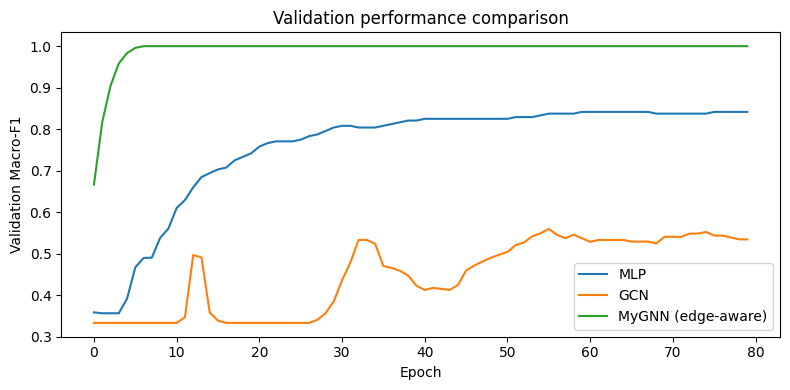

In [41]:
set_seed(42) # use the same seed for reproducibility

# TODO:
# 1) Instantiate your model
# 2) Train it using train_model
# 3) Report train/val/test F1
# 4) Plot validation curve alongside MLP and GCN

my_gnn = MyGNN(D, 64, C).to(device)
hist_my_gnn = train_model(my_gnn, lambda: my_gnn(x, src, dst, edge_w, N), epochs=80, lr=1e-3)

print("MyGNN train/val/test:", eval_model(my_gnn, lambda: my_gnn(x, src, dst, edge_w, N)))

plt.figure(figsize=(8, 4))
plt.plot(hist_mlp["val_f1"], label="MLP")
plt.plot(hist_gcn["val_f1"], label="GCN")
plt.plot(hist_my_gnn["val_f1"], label="MyGNN (edge-aware)")
plt.xlabel("Epoch")
plt.ylabel("Validation Macro-F1")
plt.title("Validation performance comparison")
plt.legend()
plt.tight_layout()
plt.show()


#### 3.3 Final Explanation

Describe:

1. What failure mode you identified in the GCN.
2. How your method addresses this failure.
3. Why your method improves performance on this dataset.
4. What assumptions your method makes about the graph.

Your answer should clearly connect:
- dataset structure,
- aggregation behavior,
- and model design.

---


**[Answer]**

1. **Failure mode**  
Vanilla mean-aggregation GCN mixes contradictory neighbor messages and underperforms (test F1 **0.4908**).

2. **How MyGNN addresses it**  
MyGNN splits aggregation into positive (`edge_w`) and negative (`1-edge_w`) channels, then combines them with a learned gate.

3. **Why performance improves**  
This preserves relation polarity and avoids destructive averaging. Colab result: MyGNN test F1 **0.9833**, far above vanilla GCN and above MLP.

4. **Assumptions**  
Edge weights carry meaningful supportive-vs-contradictory semantics, and these should be processed differently during message passing.
